# Tarea 4

## Predicción del tipo de carga eléctrica en DAEWOO Steel Co.

**Asignatura:** Minería de Datos — UTEM

---

### Resumen

Este trabajo aplica cuatro técnicas de aprendizaje supervisado al registro de consumo eléctrico de una planta siderúrgica durante 2018, con el fin de **reconocer automáticamente el tipo de carga** de la planta (liviana, media o máxima) a partir de variables eléctricas y temporales. Se comparan: (i) árboles de decisión con tres criterios de división (Gini, entropía y error de clasificación) y dos profundidades (3 y 5); (ii) Random Forest; (iii) AdaBoost; y (iv) redes bayesianas con tres estructuras distintas. Todos los modelos se entrenan con los datos de enero a septiembre y se evalúan con los de octubre a diciembre.

Los tres modelos basados en árboles alcanzan una exactitud en prueba de entre **78,3 % y 79,3 %**, con diferencias que no son relevantes en la práctica. La red bayesiana obtiene **69,2 %**, pero entrega probabilidades interpretables que permiten construir escenarios de alerta. El estudio debe entenderse como un trabajo de **reconocimiento y explicación** del régimen de carga, no como un pronóstico de la carga futura (sección 1.3). En todos los casos, la **hora del día** es el factor más determinante y la principal fuente de error es la **confusión entre carga media y carga máxima**, lo que indica que el límite de desempeño lo impone la información disponible y no el algoritmo.

## 1. Introducción y contexto

### 1.1 El problema

La planta de DAEWOO Steel Co. registra su consumo eléctrico **cada 15 minutos** durante todo 2018, lo que da **35.040 mediciones**. Cada medición está acompañada de una etiqueta que describe qué tan exigida estaba la planta en ese momento:

- **Light_Load** — carga liviana (poca maquinaria funcionando).
- **Medium_Load** — carga media.
- **Maximum_Load** — carga máxima (la planta opera a plena capacidad).

A esta etiqueta la llamaremos `Load_Type`. Conocer el tipo de carga es importante porque los periodos de **carga máxima** concentran el mayor costo eléctrico (las tarifas suelen penalizar la demanda punta) y el mayor riesgo operativo.

### 1.2 Objetivo

El objetivo es **construir modelos que aprendan de los datos históricos a reconocer el tipo de carga**, de modo que puedan formar parte de un sistema de alertas: si el modelo identifica que la planta está entrando (o ya está) en un régimen de carga máxima, se puede anticipar, redistribuir procesos o evitar penalizaciones.

En términos de minería de datos, se trata de un problema de **clasificación supervisada multiclase**: se conoce la respuesta correcta para el pasado y se busca un modelo que la reproduzca para datos nuevos.

### 1.3 Justificación práctica y alcance del estudio

Antes de continuar conviene aclarar **qué sentido tiene predecir el tipo de carga** y qué alcance tiene este trabajo.

**Cómo se define la etiqueta.** `Load_Type` se obtiene a partir del consumo medido (`Usage_kWh`). Por lo tanto, cuando el consumo ya está registrado, la etiqueta ya se conoce. Por esa razón el consumo **no se usa como variable predictora** (habría sido "copiar la respuesta"), y los modelos deben apoyarse únicamente en la hora, el tipo de día y las mediciones eléctricas de potencia reactiva y factor de potencia.

**Alcance.** Este estudio es, entonces, un trabajo de **reconocimiento y explicación** del régimen de carga, y **no un pronóstico** de la carga futura. Su valor práctico es el siguiente:

1. **Anticipación por calendario.** La hora y el tipo de día se conocen con antelación. Si el análisis muestra que, por ejemplo, las tardes de días hábiles concentran la carga máxima, la planta puede planificar turnos y procesos antes de que el consumo ocurra.
2. **Comprensión del comportamiento de la planta.** Identificar qué variables determinan la carga (y cuáles no) entrega conocimiento para la gestión energética, independientemente de que el modelo se utilice después.
3. **Verificación de consistencia.** Si el consumo registrado no concuerda con lo que indican la potencia reactiva y el factor de potencia, la diferencia puede señalar una falla de medición o un funcionamiento anómalo. En ese caso el modelo actúa como control cruzado o como sensor de respaldo.
4. **Alertas con probabilidades.** La red bayesiana entrega la **probabilidad** de carga máxima dada la información disponible, lo que permite definir umbrales de alerta graduales y no solo respuestas de "sí / no".

**Lo que este trabajo no pretende.** No predice el consumo de los próximos minutos u horas. Ese pronóstico requeriría incorporar el consumo de intervalos anteriores (que sí se conoce) y se plantea como **trabajo futuro** en la sección 8.3.

### 1.4 Un ejemplo para entender la idea: el árbol de decisión

Un árbol de decisión funciona como un **cuestionario de preguntas de sí o no** que se responden en orden, de manera similar a como razonaría un ingeniero de la planta:

1. *¿El factor de potencia inductivo es menor o igual a 80,56?* — si la respuesta es **sí**, se sigue por la rama izquierda; si es **no**, por la derecha.
2. En la rama elegida se hace otra pregunta, por ejemplo: *¿es de madrugada?*
3. Al final del recorrido se llega a una **hoja**, que entrega la respuesta: *"con estas condiciones, lo más probable es carga liviana"*.

La diferencia con un experto humano es que el árbol **construye el cuestionario por sí solo**: prueba miles de preguntas posibles (por ejemplo, *"¿la hora es anterior a las 7:00?"*) y conserva las que **mejor separan** las tres clases de carga. Una pregunta es buena cuando los grupos que genera quedan **más homogéneos**, es decir, dominados por un solo tipo de carga. Esa homogeneidad (o, al revés, la *impureza*) se mide con los tres criterios que esta tarea pide comparar:

| Criterio | Fórmula | Interpretación |
|---|---|---|
| **Gini** | $1-\sum_k p_k^2$ | Probabilidad de equivocarse si se etiqueta al azar según las proporciones del grupo. |
| **Entropía** | $-\sum_k p_k \log_2 p_k$ | Grado de "desorden" o incertidumbre del grupo. |
| **Error de clasificación** | $1-\max_k p_k$ | Proporción del grupo que se clasificaría mal si se predijera siempre la clase mayoritaria. |

donde $p_k$ es la proporción de mediciones de la clase $k$ dentro del grupo. Los tres valen **0 cuando el grupo es puro** (todas sus mediciones son de la misma clase) y crecen a medida que el grupo está más mezclado.

La principal ventaja del árbol es su **interpretabilidad**: cada camino desde la raíz hasta una hoja es una regla del tipo *"si ocurre A y B, entonces la carga es X"*, que puede ser revisada y discutida por el personal de la planta.

### 1.5 Técnicas que se comparan

| Técnica | Idea central | Analogía |
|---|---|---|
| **Árbol de decisión** | Un único cuestionario de preguntas por rangos de valores. | Un experto que sigue su protocolo. |
| **Random Forest** | Muchos árboles, cada uno entrenado con una muestra distinta de los datos; la respuesta final se decide **por votación**. | Un comité de expertos que votan. |
| **AdaBoost** | Árboles muy pequeños entrenados **en secuencia**, donde cada uno se concentra en los casos que los anteriores clasificaron mal. | Un equipo en que cada nuevo integrante corrige lo que los demás no vieron. |
| **Red bayesiana** | Un grafo que representa **qué variables influyen en cuáles**, junto con las probabilidades asociadas. | Un diagrama de causas y efectos con porcentajes. |

Los tres primeros son clasificadores orientados a **acertar**. La red bayesiana, además de clasificar, **cuantifica la incertidumbre** y permite responder preguntas del tipo *"¿qué probabilidad hay de carga máxima si es de tarde en un día hábil?"*, lo que la hace especialmente útil para un sistema de alertas.

## 2. Metodología

### 2.1 División en entrenamiento y prueba

Un modelo no se evalúa por lo que *recuerda*, sino por lo que logra con **datos que nunca vio**. Por eso los datos se dividen en dos conjuntos:

| Conjunto | Periodo | Mediciones | Días | Uso |
|---|---|---|---|---|
| **Entrenamiento** | enero – septiembre | 26.208 | 273 | El modelo aprende aquí. |
| **Prueba** | octubre – diciembre | 8.832 | 92 | Se usa solo al final, para medir el desempeño. |

La división es **cronológica** y no aleatoria: el pasado enseña y el futuro examina, tal como ocurriría si el modelo se pusiera en operación. Una división al azar daría resultados engañosamente optimistas, porque dos mediciones separadas por 15 minutos son casi idénticas; el modelo vería en el entrenamiento a la "gemela" de cada medición de prueba.

Cuando fue necesario elegir parámetros (Random Forest y AdaBoost), se hizo **solo con el conjunto de entrenamiento**, mediante validación cruzada temporal (`TimeSeriesSplit`), para que el conjunto de prueba se mantuviera completamente intacto hasta la evaluación final.

### 2.2 Métricas de evaluación

| Métrica | Pregunta que responde | Por qué se usa |
|---|---|---|
| **Accuracy (exactitud)** | ¿Qué porcentaje de mediciones se clasificó correctamente? | Medida global y fácil de comunicar. |
| **Error de clasificación** | ¿Qué porcentaje se clasificó mal? | Es $1 - \text{accuracy}$. |
| **F1 macro** | ¿Qué tan bien se clasifica **cada** clase, en promedio? | Da el mismo peso a las tres clases, por lo que no permite que una clase bien clasificada oculte a otra mal clasificada. |
| **Recall de Maximum_Load** (sensibilidad) | De todas las veces que hubo carga máxima, ¿cuántas detectó el modelo? | Es la métrica clave para alertas: una carga máxima no detectada es el error más costoso. |
| **Precision de Maximum_Load** | Cuando el modelo avisa *carga máxima*, ¿cuántas veces acierta? | Mide la cantidad de falsas alarmas. |

Como referencia, el mejor modelo de la Tarea 3 (KNN) obtuvo una exactitud de 0,78–0,79, un F1 macro cercano a 0,72 y un recall de Maximum_Load cercano a 0,60.

### 2.3 Variables utilizadas

**Variable objetivo:** `Load_Type` (Light / Medium / Maximum).

**Variables predictoras (7)** — las "pistas" que puede usar el modelo:

| Variable | Qué representa | Justificación |
|---|---|---|
| `Lagging_Current_Reactive.Power_kVarh` | Energía reactiva **inductiva**, asociada a motores, hornos y transformadores. | Aumenta cuando hay más maquinaria pesada en funcionamiento; es una huella directa de la actividad productiva. |
| `Leading_Current_Reactive_Power_kVarh` | Energía reactiva **capacitiva**. | Aparece con poca carga o con compensación de la red; complementa a la anterior. |
| `Lagging_Current_Power_Factor` | Factor de potencia inductivo (eficiencia con que se usa la energía, 0–100). | Varía de forma característica según el régimen de trabajo. |
| `Leading_Current_Power_Factor` | Factor de potencia capacitivo. | Ídem, para la componente capacitiva. |
| `WeekStatus_bin` | Día hábil (0) o fin de semana (1). | La producción no es la misma entre semana y en fin de semana. |
| `NSM_sin`, `NSM_cos` | Hora del día (`NSM`: segundos desde medianoche) transformada con seno y coseno. | Ver explicación a continuación. |

**¿Por qué la hora se transforma con seno y coseno?** Si se usa la hora como un número, para el modelo las 23:45 (23,75) y las 00:15 (0,25) parecen muy distantes, aunque solo las separan 30 minutos. Al representar la hora como la posición de un punto sobre un reloj —es decir, con su seno y su coseno— la medianoche queda junto a la medianoche y el modelo reconoce que **el día es un ciclo**.

**Variables excluidas deliberadamente:**

- `Usage_kWh` (consumo) y `CO2(tCO2)` (emisiones). La etiqueta `Load_Type` se define a partir del consumo, y las emisiones son prácticamente el consumo multiplicado por un factor. Incluirlas produciría **fuga de información** (*data leakage*): el modelo "copiaría" la respuesta en vez de aprender y lograría resultados excelentes pero inútiles, porque en un escenario real ese dato no está disponible de antemano.
- No se aplica escalamiento: los modelos basados en árboles comparan cada variable consigo misma (umbrales), por lo que no les afecta que una variable vaya de 0 a 100 y otra de −1 a 1.

## 3. Árbol de decisión

En esta sección se construyen seis árboles: tres criterios de impureza (Gini, entropía y error de clasificación) por dos profundidades máximas (3 y 5 niveles). La profundidad corresponde al número máximo de preguntas consecutivas que puede hacer el árbol. En todos los casos se exige que cada hoja contenga **al menos 20 mediciones**, para evitar reglas basadas en casos aislados.

Como `scikit-learn` solo implementa Gini y entropía, el criterio de **error de clasificación** se implementó en un árbol propio (`ArbolPropio`, en `src/modelos_aprendizaje/arbol_decision.py`), que sigue exactamente el mismo procedimiento de construcción.

In [1]:
# Celda 3.1: carga y preparación de los datos
import sys, warnings
from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from clustering import preparacion as prep_clustering
from modelos_aprendizaje import arbol_decision as ad
from modelos_aprendizaje import preparacion as prep

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)

df = prep.cargar_dataset_limpio()
X, y, fechas = prep_clustering.preparar_clasificacion(df)
X_tr, X_te, y_tr, y_te = prep_clustering.split_cronologico(X, y, fechas)
print("Train:", X_tr.shape, "| Test:", X_te.shape)
print("Variables:", list(X_tr.columns))

Train: (26208, 7) | Test: (8832, 7)
Variables: ['Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'WeekStatus_bin', 'NSM_sin', 'NSM_cos']


**Resultado.** Los datos quedan divididos en **26.208 mediciones de entrenamiento** y **8.832 de prueba**, ambas con las mismas **7 variables predictoras** descritas en la sección 2.3. Todos los modelos de este trabajo usan exactamente esta misma división, lo que permite compararlos en igualdad de condiciones.

In [2]:
# Celda 3.2: comparación de los tres criterios con profundidad 3 y 5
tabla, modelos, preds = ad.comparar_criterios(X_tr, X_te, y_tr, y_te, profundidades=(3, 5))
tabla

,Criterio,Profundidad,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Prof_real,N_hojas
0,Gini,3,0.7906,0.6214,0.3786,0.5865,0.5625,3,8
1,Gini,5,0.8805,0.7885,0.2115,0.7194,0.5998,5,25
2,Entropía,3,0.7427,0.6687,0.3313,0.6115,0.7999,3,8
3,Entropía,5,0.8776,0.7835,0.2165,0.7117,0.5663,5,25
4,Error de clasificación,3,0.8574,0.7353,0.2647,0.6778,0.5696,3,8
5,Error de clasificación,5,0.8921,0.7692,0.2308,0.7104,0.5685,5,22


**Cómo leer la tabla.** Cada fila corresponde a un árbol. Las columnas `_train` indican el desempeño sobre los datos con que el árbol aprendió y las columnas `_test`, sobre datos que nunca vio; **las que importan para juzgar el modelo son las de prueba**. `Prof_real` es la profundidad efectivamente alcanzada y `N_hojas`, el número de respuestas finales (reglas) del árbol.

**Interpretación.**

1. **La profundidad es más determinante que el criterio.** Con 3 niveles, la exactitud en prueba varía entre 62 % y 74 %: tres preguntas no bastan para separar tres tipos de carga. Con 5 niveles, los tres criterios convergen a **77–79 %** y a un F1 macro de **0,71–0,72**.
2. **Los criterios producen resultados similares.** Gini, entropía y error de clasificación miden lo mismo —qué tan mezclado queda un grupo— con fórmulas distintas, y con profundidad suficiente terminan encontrando cortes parecidos. Gini y entropía son casi equivalentes. El error de clasificación es menos sensible a mejoras pequeñas de pureza, por lo que a profundidad 3 elige divisiones diferentes (que en este caso resultaron mejores, 0,7353), pero a profundidad 5 queda levemente por debajo (0,7692).
3. **Un recall alto no siempre es una virtud.** El árbol de entropía con profundidad 3 detecta el 80 % de las cargas máximas, pero su exactitud global es baja (0,6687): lo logra **prediciendo carga máxima con demasiada frecuencia**, lo que en la práctica generaría muchas falsas alarmas.
4. **Sobreajuste.** En profundidad 5, la exactitud baja de 0,88 en entrenamiento a 0,79 en prueba. Esa diferencia indica que parte de lo aprendido es específico de los meses de entrenamiento y no se repite en el último trimestre.

**Conclusión parcial.** Se selecciona el árbol **Gini de profundidad 5** como representante del árbol de decisión para la comparación final, por tener la mayor exactitud y el mayor F1 macro en prueba.

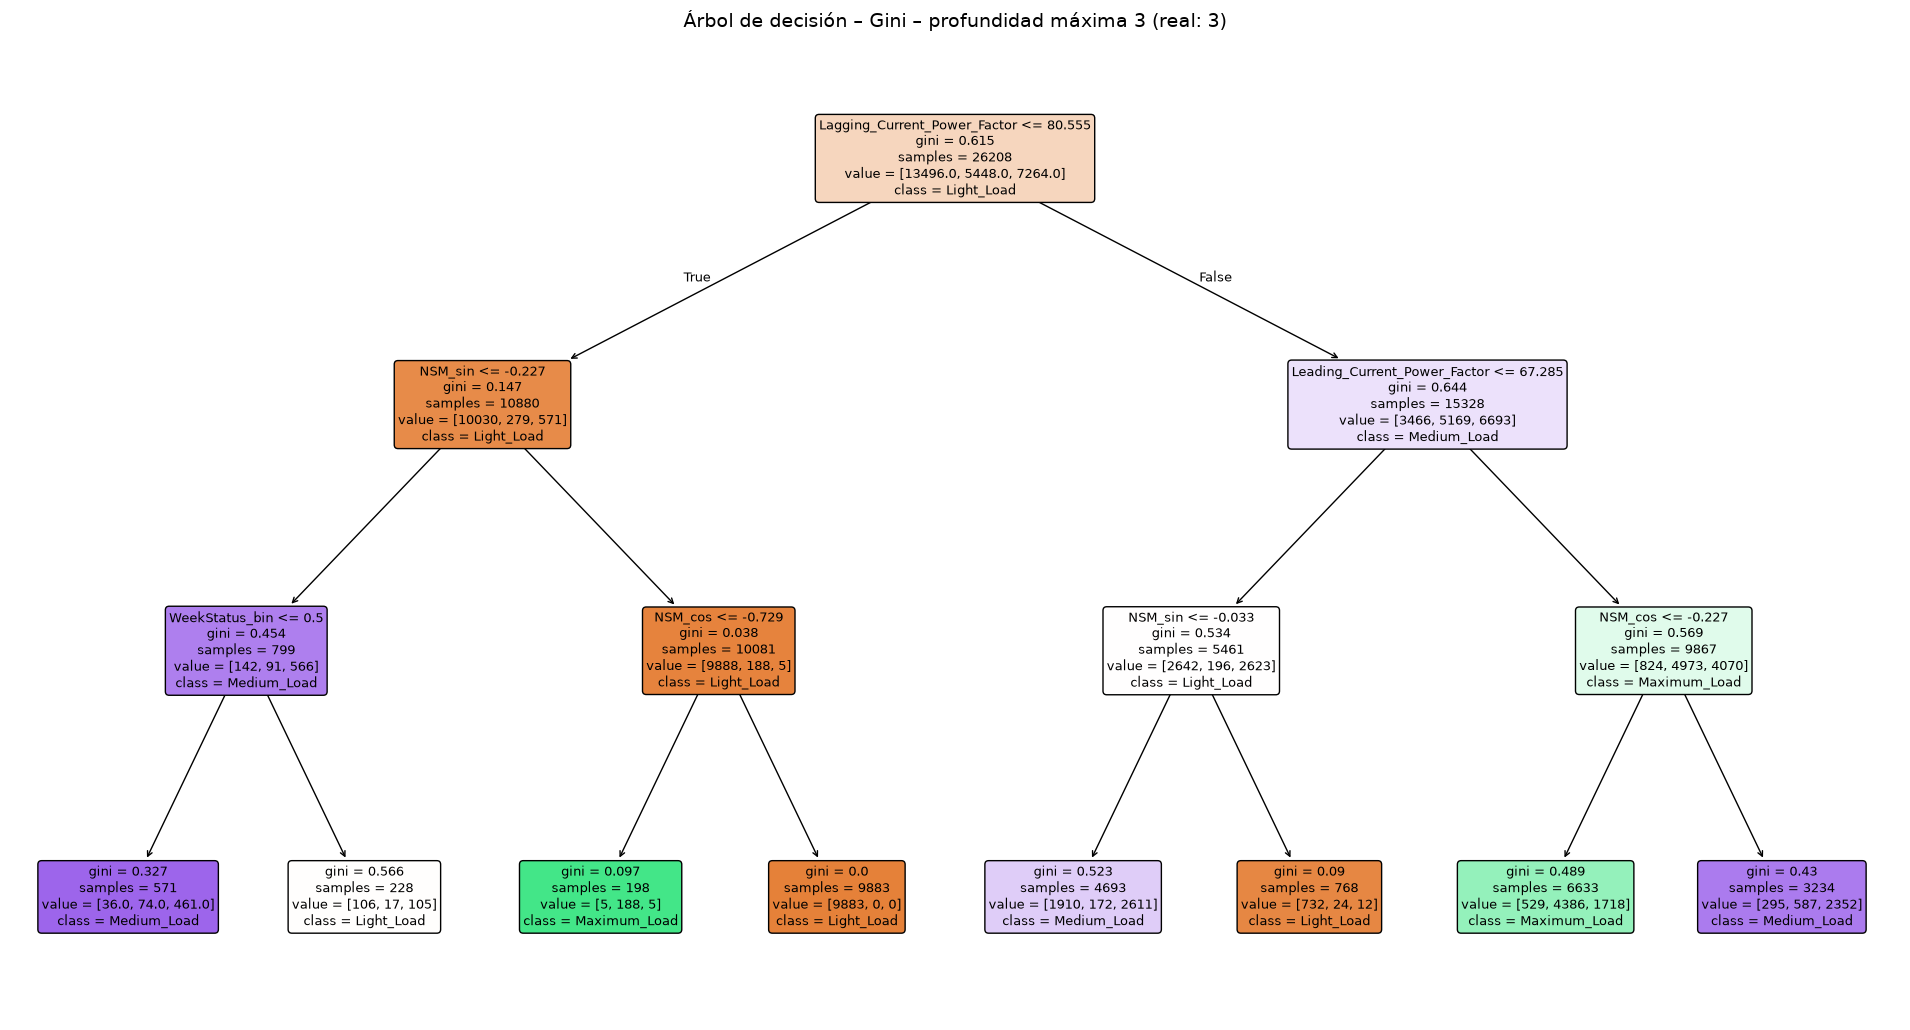

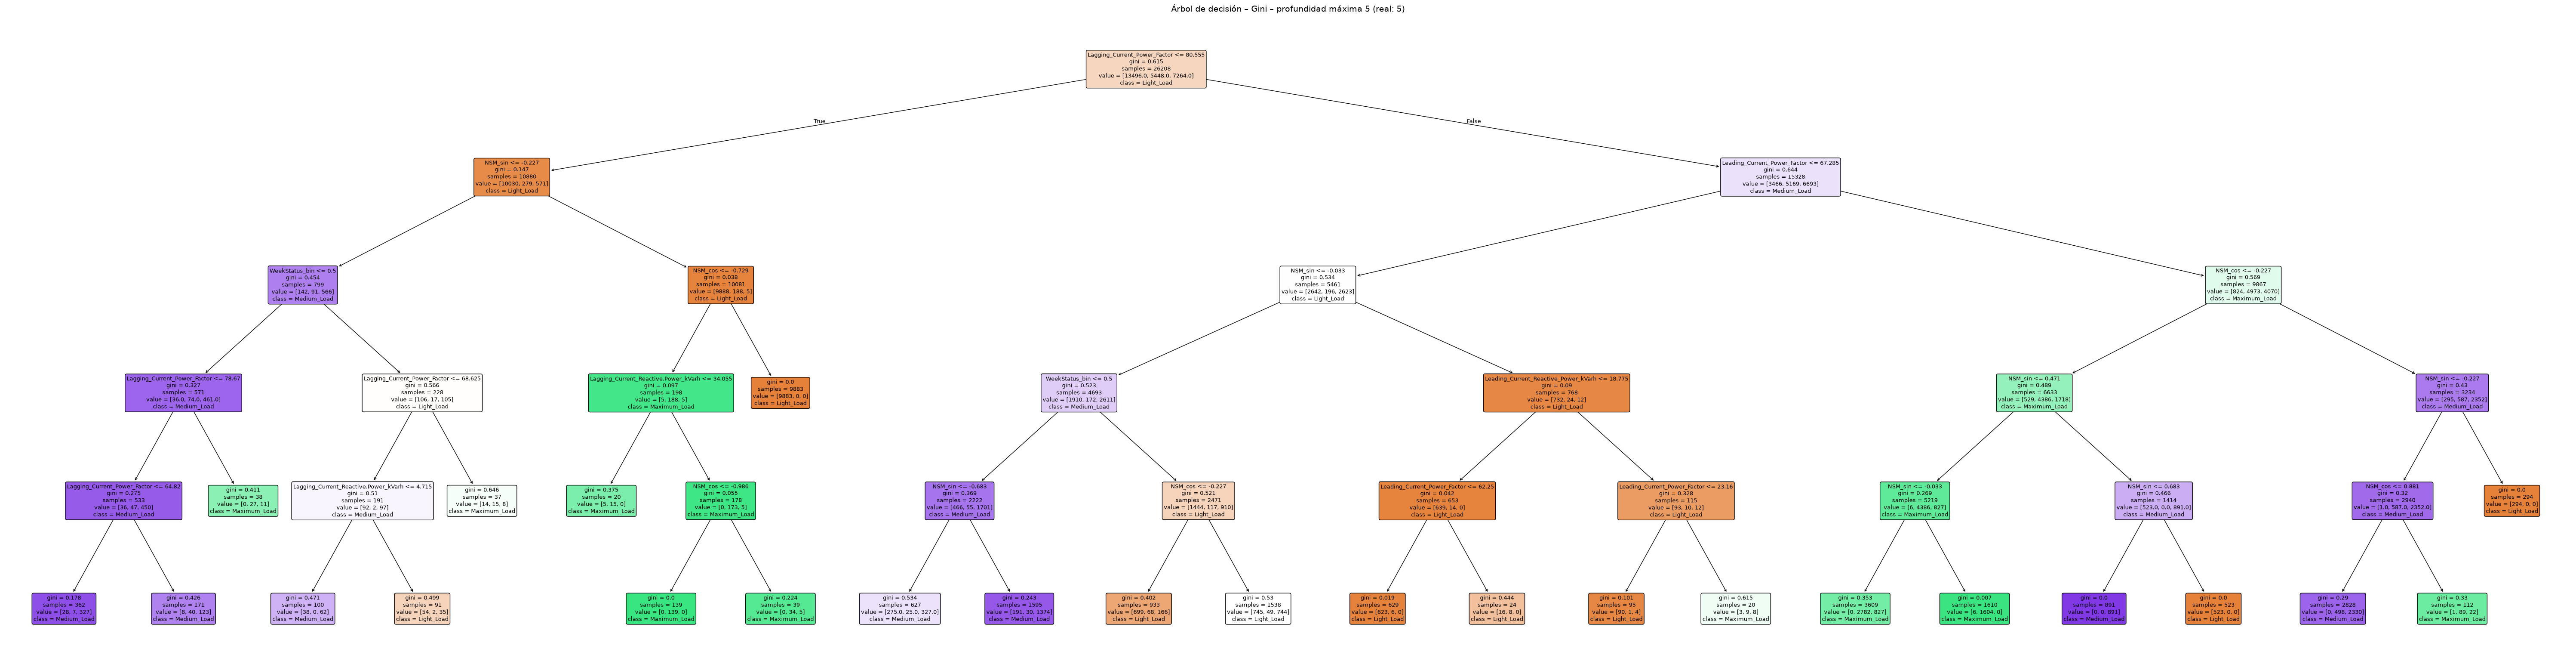

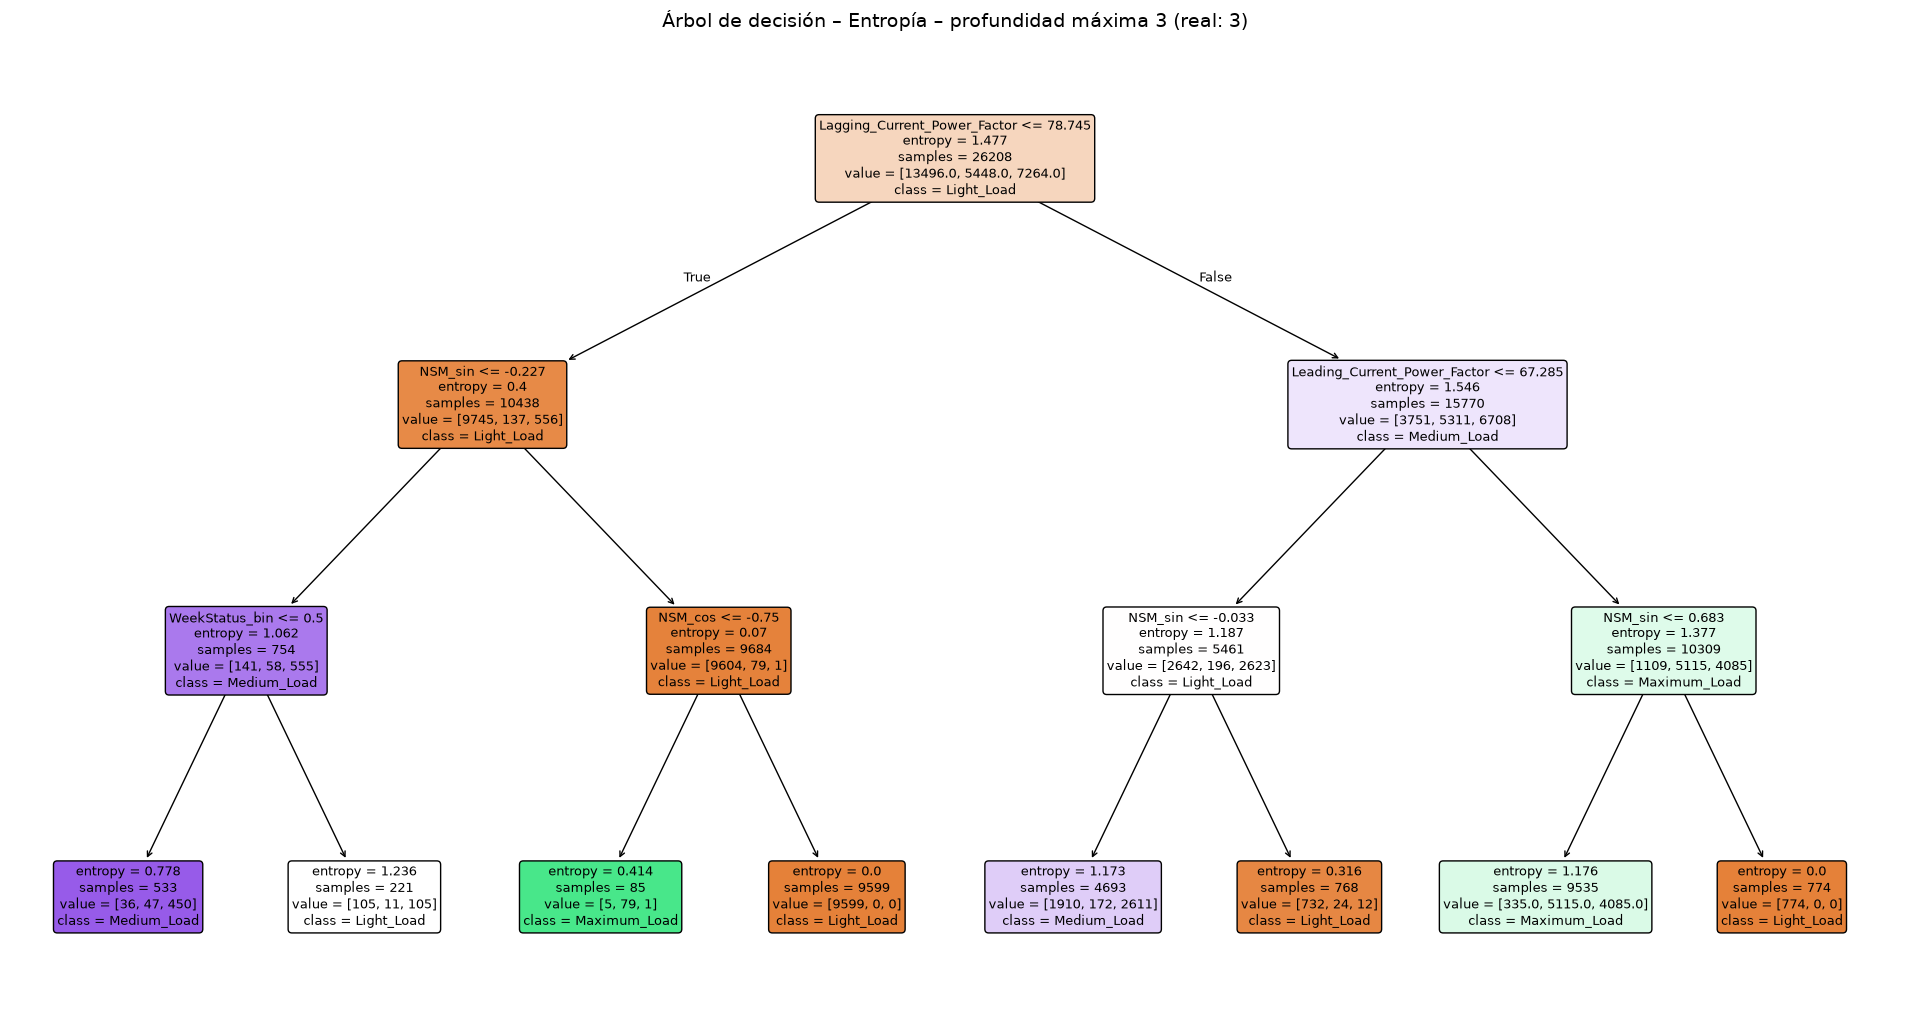

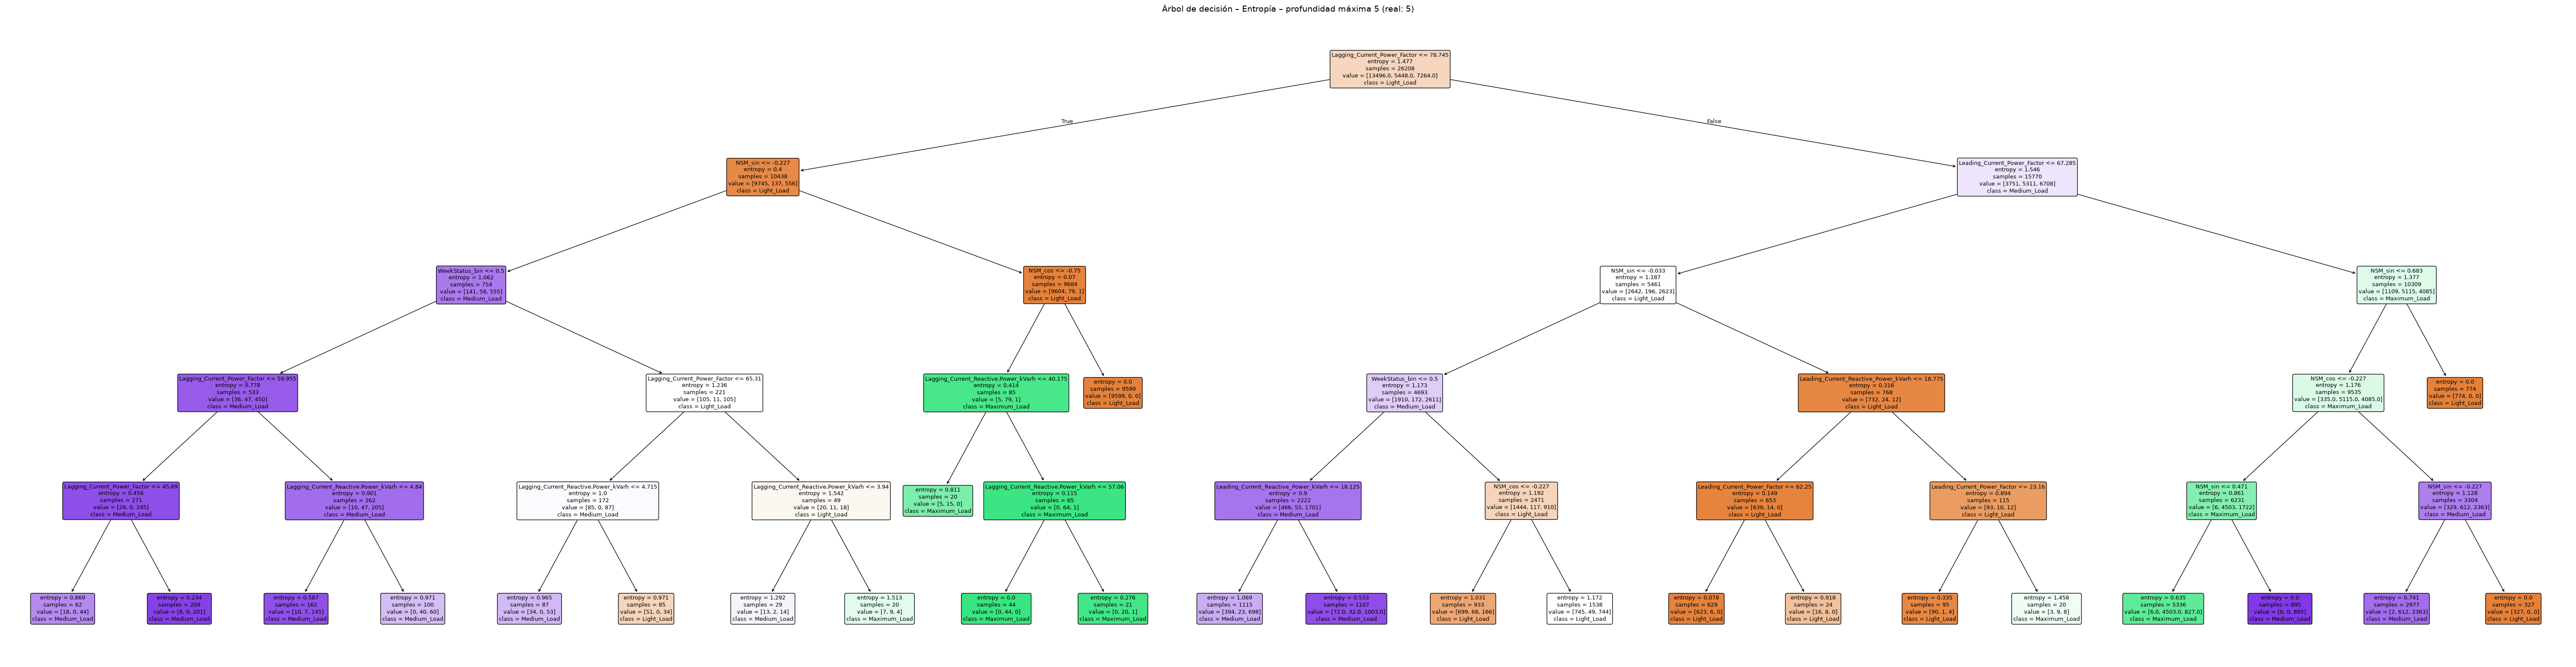

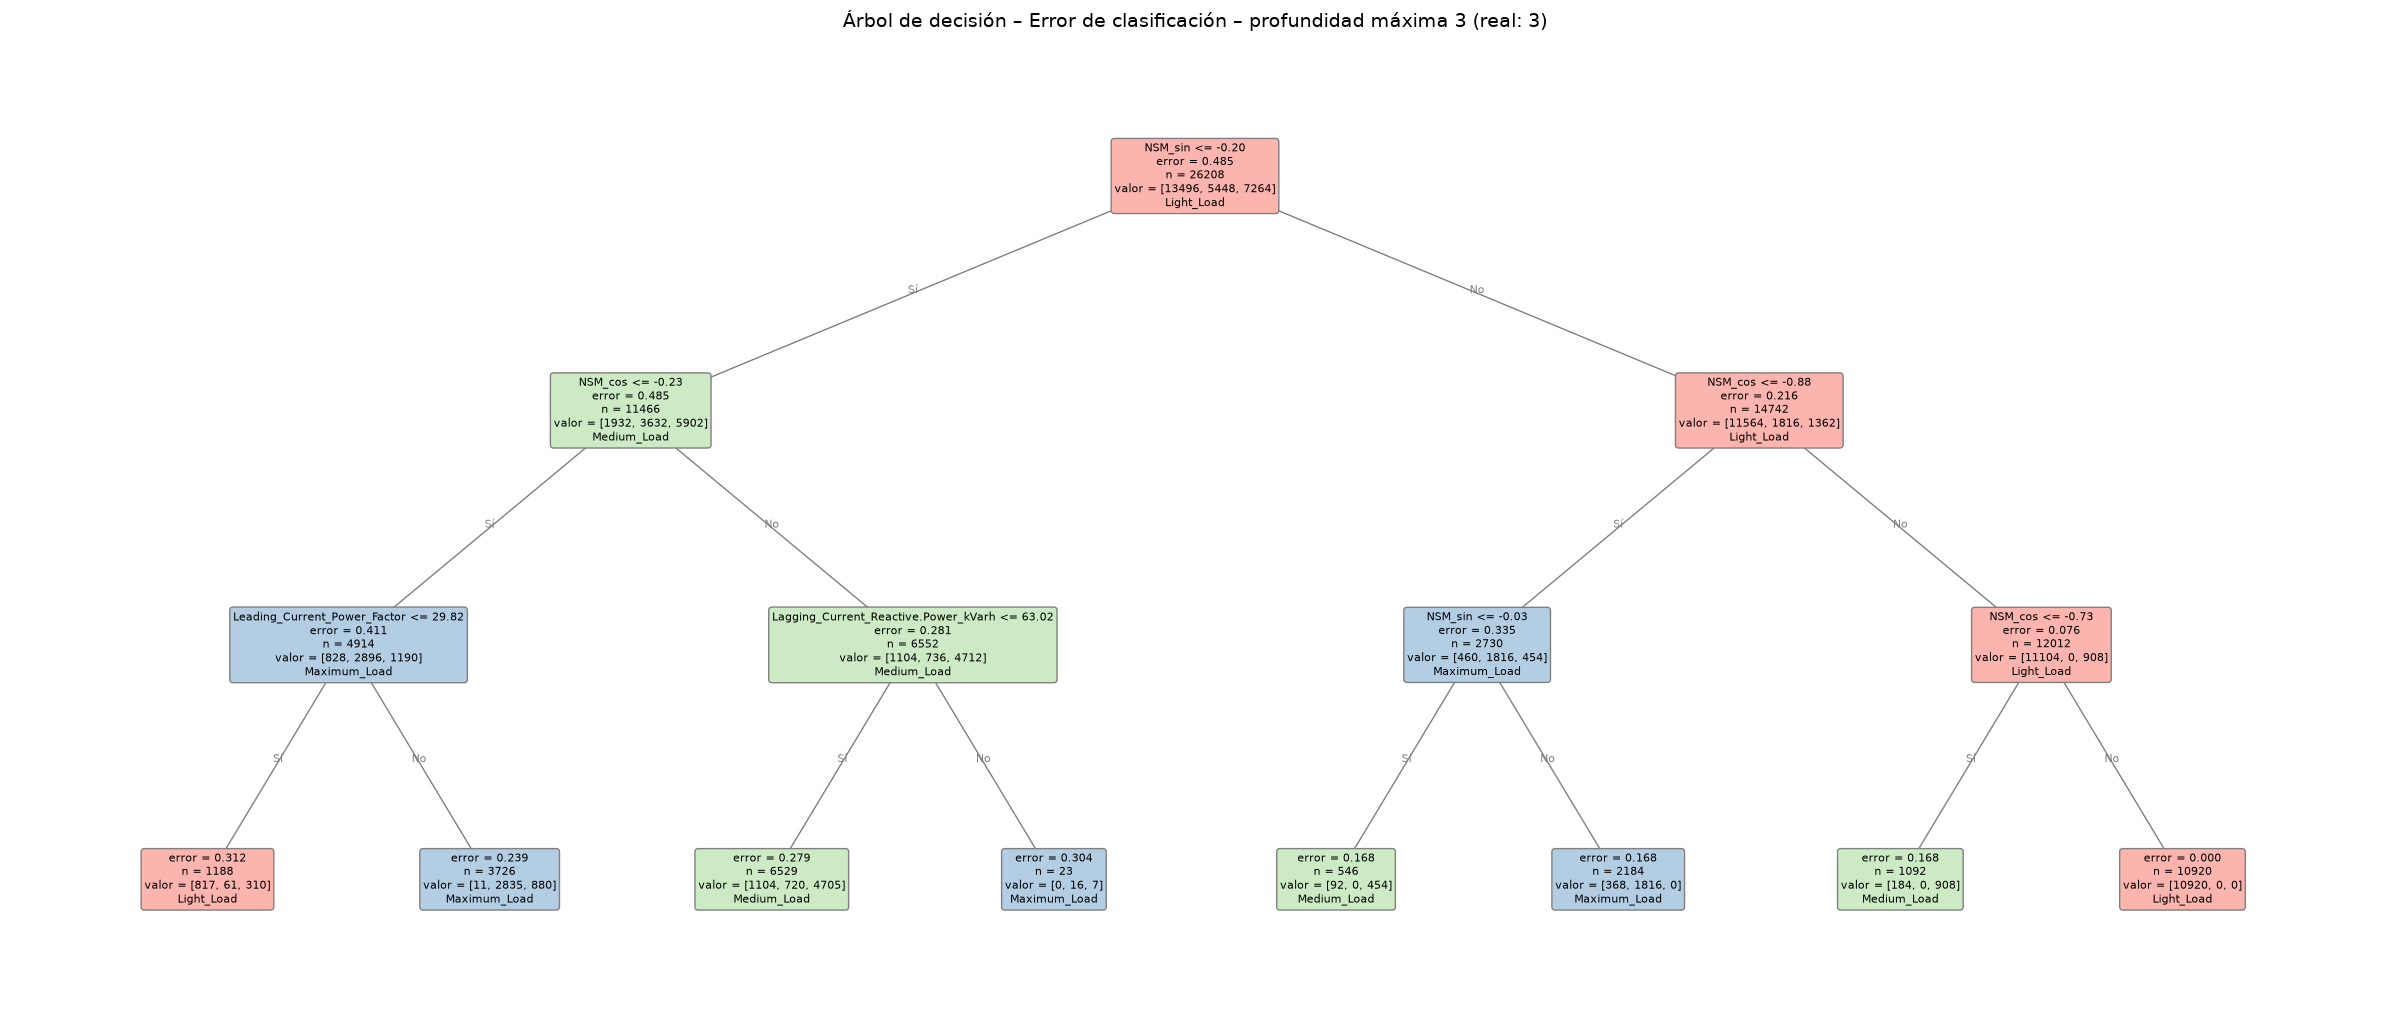

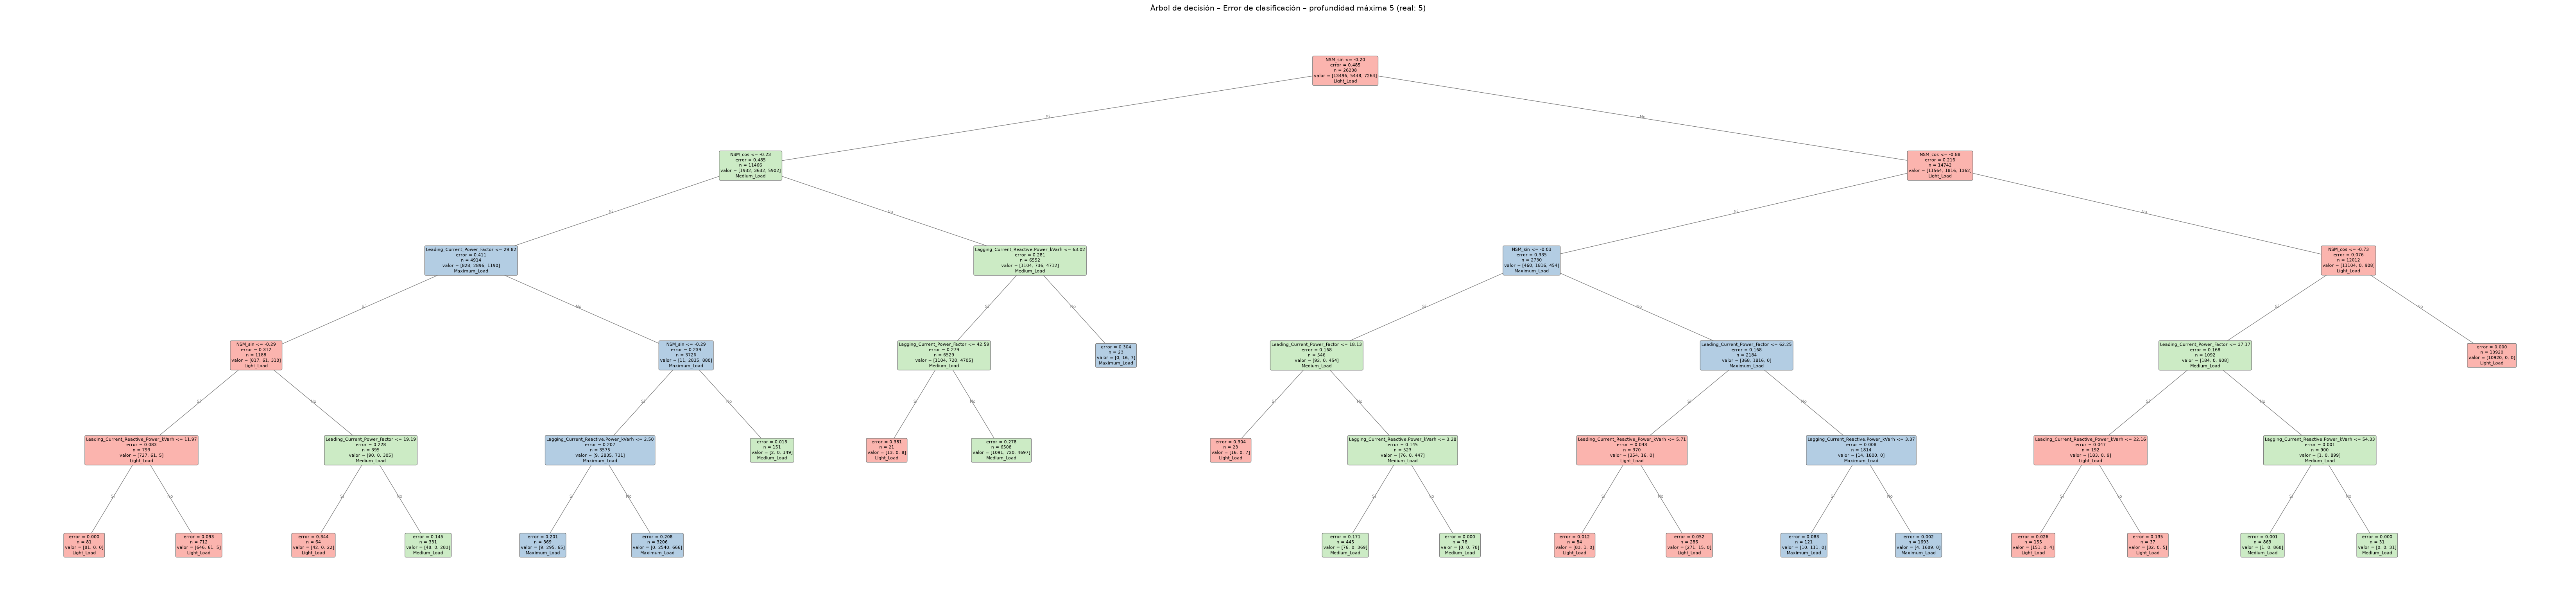

In [3]:
# Celda 3.3: gráficos de los seis árboles
_ = ad.graficar_arboles(modelos, list(X_tr.columns))

**Cómo leer los gráficos.** El árbol se recorre de arriba hacia abajo. Cada recuadro (nodo) contiene:

- la **pregunta** que se hace (por ejemplo, `Lagging_Current_Power_Factor <= 80.56`): si se cumple, se continúa por la rama **izquierda**; si no, por la **derecha**;
- el valor de **impureza** del grupo según el criterio usado: mientras más cercano a 0, más homogéneo es el grupo;
- el número de mediciones que llegan a ese nodo (`samples`) y cuántas hay de cada clase (`value`);
- la **clase predominante** (`class`).

El **color** indica la clase predominante (según la leyenda) y su **intensidad**, la pureza del grupo: un color fuerte significa que casi todas las mediciones del nodo son de la misma clase. Los recuadros del último nivel son las **hojas**, es decir, las respuestas finales del modelo.

**Interpretación.**

- La **pregunta de la raíz** es la que, de todas las posibles, mejor separa los datos. En el árbol de Gini corresponde al **factor de potencia inductivo** (`Lagging_Current_Power_Factor <= 80.56`), y en los niveles siguientes aparecen sobre todo las variables de **hora** (`NSM_sin`, `NSM_cos`) y el **tipo de día**. Es decir, el árbol combina una condición eléctrica con el momento del día.
- Muy pronto aparecen hojas casi puras de **carga liviana**: con Gini, una sola hoja reúne 9.883 mediciones (37,7 % del entrenamiento) y con error de clasificación, 10.920 (41,7 %). La carga liviana es, por lo tanto, **fácil de reconocer**; lo difícil es distinguir entre carga media y máxima, cuyas hojas tienen colores menos intensos (grupos más mezclados).
- Los árboles de **profundidad 3** pueden leerse completos. Los de **profundidad 5** tienen hasta 25 hojas: son más precisos, pero su imagen resulta difícil de leer, por lo que para interpretarlos conviene usar las reglas en texto (celda 3.5).

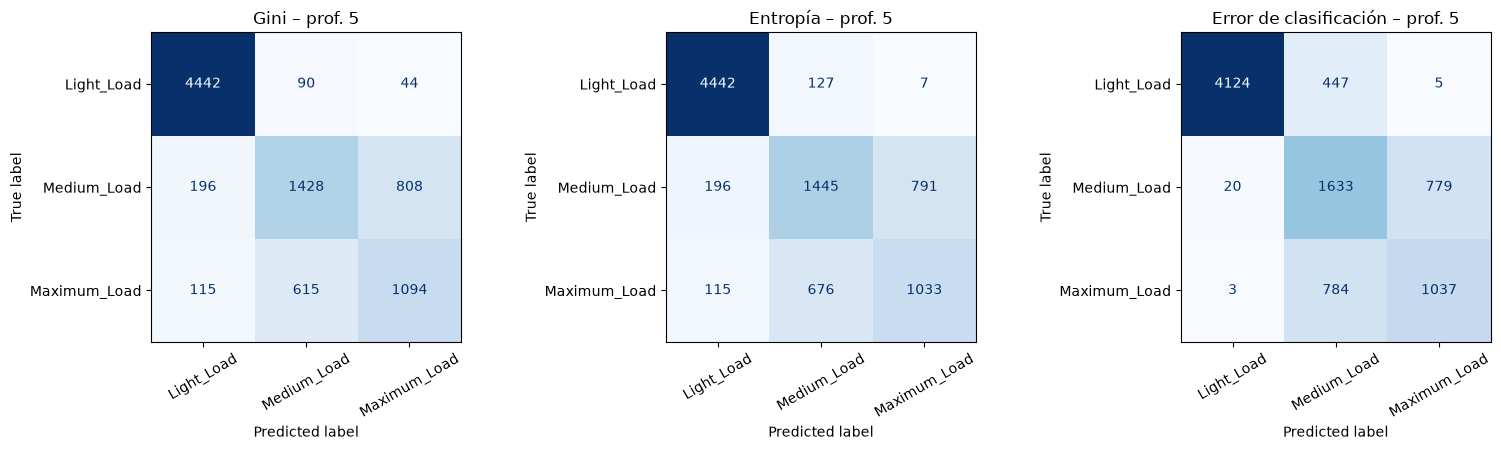

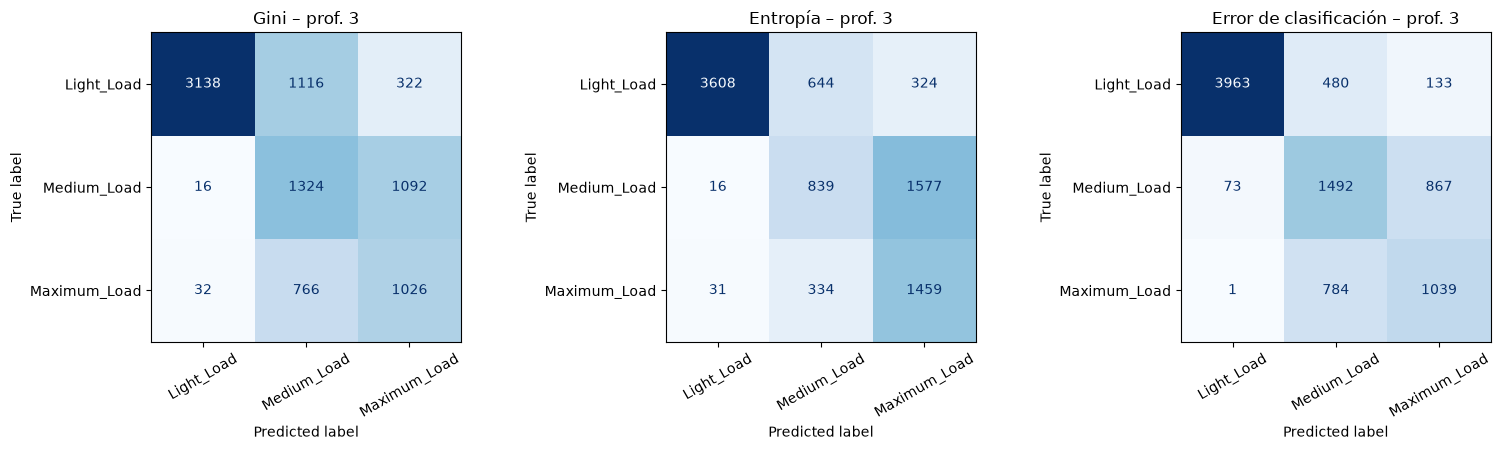

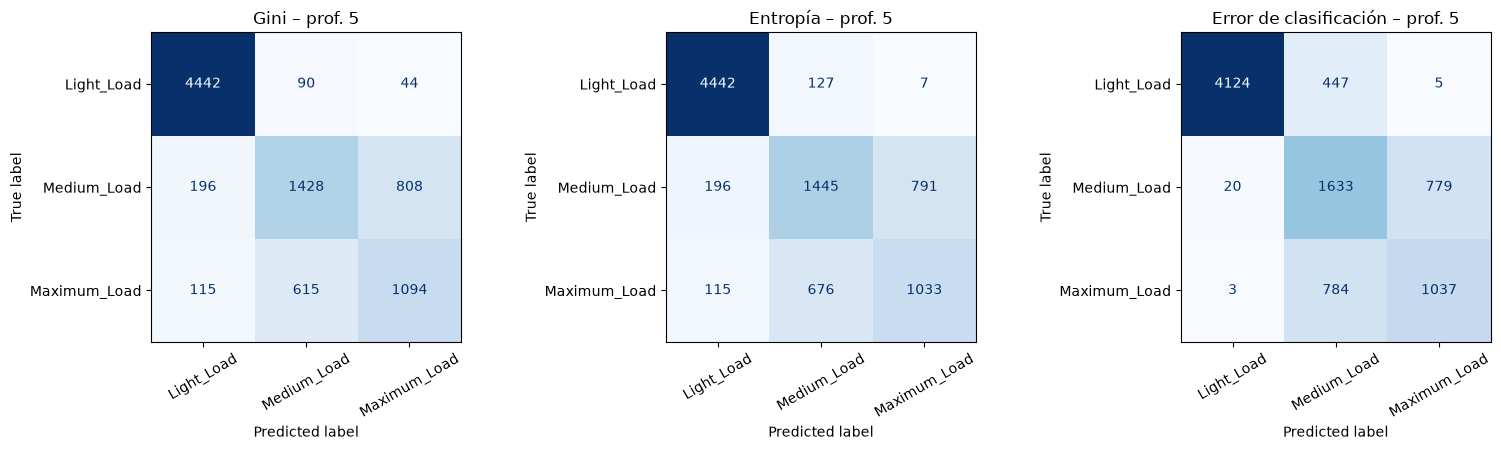

In [4]:
# Celda 3.4: matrices de confusión (profundidad 3 y 5)
ad.graficar_matrices_confusion(preds, y_te, 3, prep_clustering.ORDEN_CARGA)
ad.graficar_matrices_confusion(preds, y_te, 5, prep_clustering.ORDEN_CARGA)

**Cómo leer una matriz de confusión.** Es una tabla de aciertos y errores sobre el conjunto de prueba. Las **filas** indican la clase real y las **columnas**, la clase predicha. La **diagonal** (de arriba a la izquierda hacia abajo a la derecha) contiene los **aciertos**; cualquier valor fuera de ella es un error. Los tonos más oscuros señalan más casos.

**Interpretación.** Tomando como ejemplo el árbol Gini de profundidad 5:

| Real \ Predicho | Light | Medium | Maximum |
|---|---|---|---|
| **Light** | **4.442** | 90 | 44 |
| **Medium** | 196 | **1.428** | 808 |
| **Maximum** | 115 | 615 | **1.094** |

- La **carga liviana** se reconoce casi siempre: 4.442 de 4.576 casos (97 %).
- Los errores se concentran entre **carga media y máxima**: 808 mediciones de carga media se clasificaron como máxima y 615 de carga máxima se clasificaron como media. Solo esas dos celdas suman 1.423 de los 1.868 errores, es decir, **el 76 % de todos los errores**.
- Este patrón se repite en los seis árboles (y, como se verá, en todos los modelos del trabajo). La razón es que, con las variables disponibles, la carga media y la máxima **presentan valores eléctricos muy parecidos** y el límite entre ambas es difuso.

Para un sistema de alertas, la celda *Maximum real → Medium predicho* (615 casos) es la más crítica: corresponde a cargas máximas que **no se habrían alertado**.

|--- Lagging_Current_Power_Factor <= 80.56
|   |--- NSM_sin <= -0.23
|   |   |--- WeekStatus_bin <= 0.50
|   |   |   |--- class: Medium_Load
|   |   |--- WeekStatus_bin >  0.50
|   |   |   |--- class: Light_Load
|   |--- NSM_sin >  -0.23
|   |   |--- NSM_cos <= -0.73
|   |   |   |--- class: Maximum_Load
|   |   |--- NSM_cos >  -0.73
|   |   |   |--- class: Light_Load
|--- Lagging_Current_Power_Factor >  80.56
|   |--- Leading_Current_Power_Factor <= 67.28
|   |   |--- NSM_sin <= -0.03
|   |   |   |--- class: Medium_Load
|   |   |--- NSM_sin >  -0.03
|   |   |   |--- class: Light_Load
|   |--- Leading_Current_Power_Factor >  67.28
|   |   |--- NSM_cos <= -0.23
|   |   |   |--- class: Maximum_Load
|   |   |--- NSM_cos >  -0.23
|   |   |   |--- class: Medium_Load



,Gini,Entropía,Error de clasificación
Lagging_Current_Reactive.Power_kVarh,0.0006,0.0025,0.0009
Leading_Current_Reactive_Power_kVarh,0.0004,0.0093,0.0000
Lagging_Current_Power_Factor,0.3991,0.3678,0.0005
Leading_Current_Power_Factor,0.1169,0.1353,0.1312
WeekStatus_bin,0.0338,0.0242,0.0000
NSM_sin,0.3199,0.3555,0.4844
NSM_cos,0.1294,0.1054,0.3830


,Criterio,Profundidad,Accuracy_train,Accuracy_test
0,Gini,1,0.6381,0.5930
1,Gini,2,0.6894,0.5998
2,Gini,3,0.7906,0.6214
3,Gini,4,0.8570,0.7491
4,Gini,5,0.8805,0.7885
5,Gini,6,0.8964,0.7897
6,Gini,7,0.9021,0.7862
7,Gini,8,0.9051,0.7934
8,Gini,9,0.9104,0.7797
9,Gini,10,0.9137,0.7828


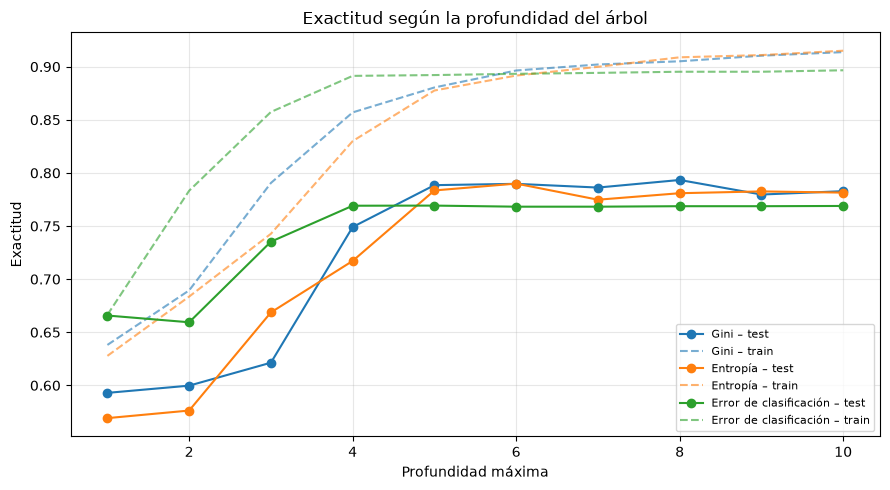

In [5]:
# Celda 3.5: reglas del árbol, importancia de variables y curva de profundidad
print(ad.reglas_texto(modelos[("gini", 3)], list(X_tr.columns)))

display(ad.tabla_importancias(modelos, X_tr.columns, 5))

curva_prof = ad.curva_profundidad(X_tr, X_te, y_tr, y_te, range(1, 11))
display(curva_prof)
ad.graficar_curva_profundidad(curva_prof);

**Reglas del árbol.** El texto anterior es el árbol Gini de profundidad 3 escrito como reglas. Cada línea con `|---` es una condición y cada `class:` es una conclusión. Por ejemplo, la segunda rama se lee:

> *Si el factor de potencia inductivo es **menor o igual a 80,56**, `NSM_sin > −0,23` y `NSM_cos ≤ −0,73`, entonces la carga es **máxima**.*

Las condiciones sobre `NSM_sin` y `NSM_cos` equivalen a una franja horaria. Así, el árbol puede traducirse en enunciados que el personal de la planta puede validar, del tipo *"cuando el factor de potencia cae por debajo de 80 en determinada franja del día, la planta entra en carga máxima"*. Se observa además que **las ocho hojas pasan por al menos una condición sobre la hora** y que el tipo de día (`WeekStatus_bin`) solo interviene en una rama, para distinguir carga media de liviana.

**Importancia de variables.** La tabla indica cuánto contribuyó cada variable a reducir la impureza en los árboles de profundidad 5. Una variable con importancia alta es una que el árbol usa en preguntas cercanas a la raíz o en muchos nodos.

**Curva de profundidad.** El gráfico muestra la exactitud en entrenamiento (línea punteada) y en prueba (línea continua) para profundidades de 1 a 10. La curva de **entrenamiento sube siempre** al aumentar la profundidad, porque el árbol se ajusta cada vez más a los datos que ya vio. La de **prueba**, en cambio, mejora hasta cierta profundidad y luego se estabiliza o empeora: a partir de ese punto, las preguntas adicionales capturan particularidades del periodo de entrenamiento que no se repiten en el de prueba (**sobreajuste**). La profundidad 5 se ubica en la zona donde el desempeño de prueba ya se estabilizó, lo que justifica su elección.

> *Nota:* complete este párrafo con los valores concretos de la curva (profundidad en que la exactitud de prueba alcanza su máximo).

## 4. Random Forest

Random Forest construye **muchos árboles distintos** y combina sus predicciones por votación. La diversidad entre árboles se logra de dos formas:

1. cada árbol se entrena con una **muestra aleatoria con reemplazo** de los datos (*bootstrap*);
2. en cada pregunta, el árbol solo puede elegir entre un **subconjunto aleatorio de variables** (`max_features`).

Como cada árbol se equivoca de manera distinta, al votar los errores individuales tienden a compensarse. Esto suele reducir la varianza del modelo, es decir, su tendencia a sobreajustarse.

In [6]:
# Celda 4.1: importar el módulo
from modelos_aprendizaje import random_forest as rf

In [7]:
# Celda 4.2: elección de hiperparámetros con validación cruzada temporal (solo entrenamiento)
mejores, tabla_cv = rf.buscar_hiperparametros(X_tr, y_tr)
print("Mejores parámetros:", mejores)
tabla_cv.head(10)

Mejores parámetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 200}


,max_depth,max_features,min_samples_leaf,n_estimators,F1_macro_CV,Desv_CV,Ranking
0,None,sqrt,5,200,0.8279,0.0950,1
1,10,0.5000,5,200,0.8274,0.1045,2
2,None,0.5000,5,200,0.8272,0.0927,3
3,10,sqrt,5,200,0.8265,0.1043,4
4,None,sqrt,20,200,0.8251,0.0997,5
5,10,sqrt,20,200,0.8233,0.1067,6
6,10,0.5000,20,200,0.8227,0.1049,7
7,10,sqrt,50,200,0.8216,0.1138,8
8,None,sqrt,50,200,0.8211,0.1126,9
9,None,0.5000,20,200,0.8204,0.0983,10


**Qué muestra la tabla.** Antes de entrenar el modelo definitivo se evaluaron distintas configuraciones (*hiperparámetros*): profundidad máxima de los árboles (`max_depth`), número de variables candidatas por pregunta (`max_features`) y tamaño mínimo de las hojas (`min_samples_leaf`). Cada configuración se evaluó **solo con los datos de entrenamiento**, dividiéndolos en bloques cronológicos. `F1_macro_CV` es el desempeño promedio en esos bloques, `Desv_CV` su variabilidad y `Ranking` el orden resultante.

**Interpretación.**

- La mejor configuración utiliza árboles **sin límite de profundidad**, hojas de al menos **5 mediciones** y la **raíz cuadrada** del número de variables en cada pregunta, con un F1 de validación de **0,8279**.
- Las diez mejores configuraciones están entre 0,820 y 0,828: el modelo es **poco sensible** a estos ajustes.
- La desviación (≈ 0,10) es elevada: el desempeño cambia bastante según el bloque temporal evaluado, lo que sugiere que **no todos los meses se comportan igual**.

In [8]:
# Celda 4.3: entrenamiento y evaluación del modelo final
modelo = rf.entrenar_random_forest(X_tr, y_tr, **mejores)
metricas, pred = rf.evaluar_modelo(modelo, X_tr, X_te, y_tr, y_te)
pd.DataFrame([metricas])

,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,0.9502,0.7833,0.2167,0.7194,0.5806,0.5765


**Resultados.** El bosque alcanza una exactitud de **0,9502 en entrenamiento** y **0,7833 en prueba**, un F1 macro de **0,7194**, un recall de carga máxima de **0,5806** (detecta cerca de 6 de cada 10 cargas máximas) y una precisión de **0,5765** (algo más de la mitad de sus alertas de carga máxima son correctas).

**Interpretación.** La diferencia entre 0,95 y 0,78 muestra que el bosque **reproduce casi perfectamente el periodo de entrenamiento**, pero esa capacidad no se traduce en una mejor predicción del último trimestre. Además, el F1 de validación (≈ 0,83) es claramente mayor que el de prueba (0,72), lo que indica que **octubre–diciembre es un periodo más difícil** que los meses usados para validar, posiblemente por cambios estacionales en la operación de la planta.

,N_arboles,Accuracy_train,Accuracy_test,F1_macro_test
0,1,0.9169,0.7595,0.7067
1,5,0.9402,0.7866,0.7245
2,10,0.9458,0.7862,0.7225
3,25,0.9481,0.7850,0.7220
4,50,0.9504,0.7835,0.7202
5,100,0.9499,0.7839,0.7201
6,200,0.9502,0.7833,0.7194
7,300,0.9502,0.7828,0.7191


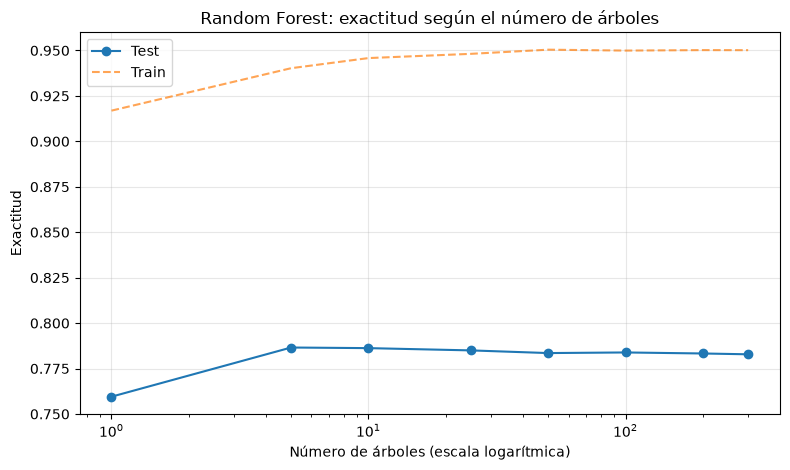

In [9]:
# Celda 4.4: efecto del número de árboles (con los mismos hiperparámetros del modelo final)
curva = rf.curva_n_arboles(X_tr, X_te, y_tr, y_te,
                           max_depth=mejores["max_depth"],
                           max_features=mejores["max_features"],
                           min_samples_leaf=mejores["min_samples_leaf"])
display(curva)
rf.graficar_curva_n_arboles(curva);

**Cómo leer el gráfico.** El eje horizontal (en escala logarítmica) indica el número de árboles del bosque y el vertical, la exactitud. La línea punteada corresponde al entrenamiento y la continua, a la prueba.

**Interpretación.** La exactitud de prueba mejora levemente al pasar de 1 a 5 árboles y desde ahí **se mantiene prácticamente constante**, aunque se agreguen cientos de árboles. Esto significa que con una decena de árboles ya se obtiene todo el beneficio de la votación; agregar más solo aumenta el costo computacional. Es un comportamiento esperado: en Random Forest, más árboles nunca empeoran el modelo, pero la ganancia se satura rápidamente.

> *Nota:* esta celda se corrigió para usar los mismos hiperparámetros del modelo final (en la versión anterior se usaba `min_samples_leaf=20`, por lo que la curva no coincidía con el modelo evaluado). Actualice las cifras de este párrafo tras volver a ejecutarla.

,Modelo,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,"Árbol único (Gini, prof. 5)",0.8805,0.7885,0.2115,0.7194,0.5998,0.5622
1,Random Forest,0.9502,0.7833,0.2167,0.7194,0.5806,0.5765


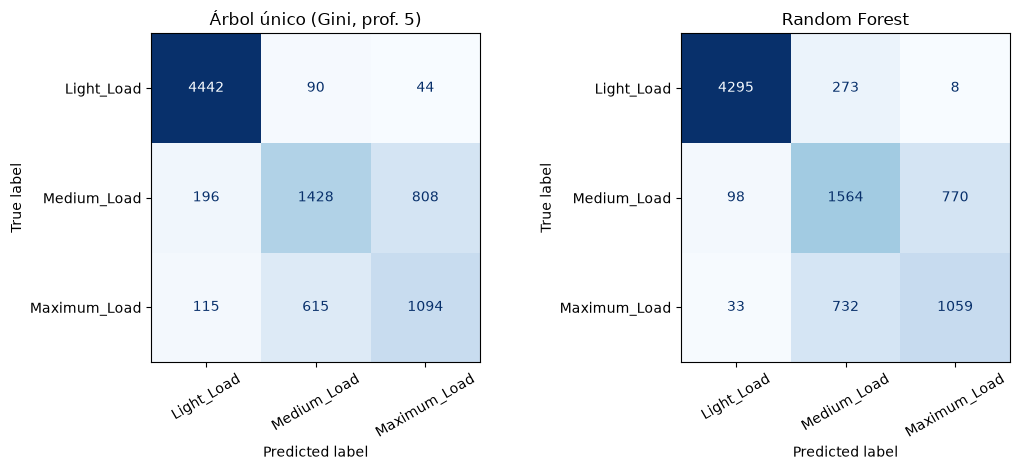

In [10]:
# Celda 4.5: bosque frente a un árbol único, y matrices de confusión
tabla_cmp, modelos_cmp, preds_cmp = rf.comparar_bosque_vs_arbol(X_tr, X_te, y_tr, y_te, mejores)
display(tabla_cmp)
rf.graficar_matrices_confusion(preds_cmp, y_te);

**Resultados.**

| Modelo | Exactitud entrenamiento | Exactitud prueba | F1 macro | Recall Maximum | Precision Maximum |
|---|---|---|---|---|---|
| Árbol único (Gini, prof. 5) | 0,8805 | **0,7885** | 0,7194 | **0,5998** | 0,5622 |
| Random Forest | **0,9502** | 0,7833 | 0,7194 | 0,5806 | **0,5765** |

**Interpretación.** **El bosque no supera al árbol único en el conjunto de prueba**: ambos tienen el mismo F1 macro y la exactitud del árbol es incluso levemente mayor. Las matrices de confusión muestran el mismo patrón en los dos modelos: la carga liviana se reconoce casi siempre y los errores se concentran entre carga media y máxima. El bosque genera algo menos de falsas alarmas (precisión 0,5765 frente a 0,5622), pero detecta algo menos de cargas máximas (recall 0,5806 frente a 0,5998).

Este resultado es relevante: Random Forest corrige errores debidos a la **inestabilidad** de un árbol individual, pero no puede corregir errores debidos a que **la información no alcanza** para separar dos clases. El hecho de que no mejore indica que el problema pertenece al segundo tipo.

,Imp_impureza,Imp_permutacion,Desv_permutacion
NSM_sin,0.2824,0.2737,0.0038
NSM_cos,0.2102,0.0983,0.0037
Leading_Current_Power_Factor,0.0849,0.0326,0.0011
Leading_Current_Reactive_Power_kVarh,0.0615,0.0051,0.0005
Lagging_Current_Power_Factor,0.1983,0.0009,0.0011
WeekStatus_bin,0.0278,0.0001,0.0016
Lagging_Current_Reactive.Power_kVarh,0.1349,-0.0005,0.0021


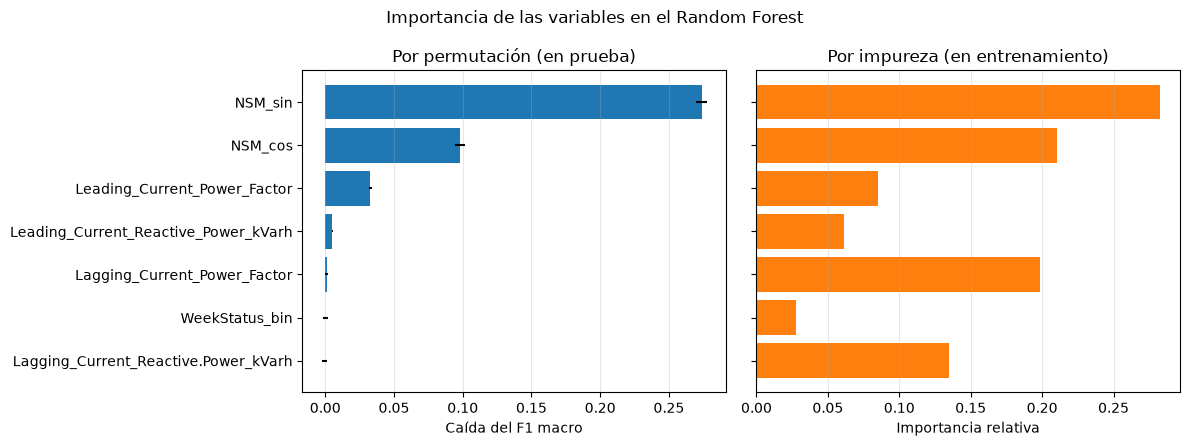

In [11]:
# Celda 4.6: importancia de las variables
imp = rf.tabla_importancias(modelo, X_te, y_te)
display(imp)
rf.graficar_importancias(imp);

**Cómo leer el gráfico.** Se presentan dos medidas de importancia:

- **Por permutación (izquierda):** se desordenan al azar los valores de una variable en los datos de prueba y se mide cuánto empeora el modelo. Si empeora mucho, la variable era importante. Es la medida **más confiable**, porque se calcula sobre datos no vistos.
- **Por impureza (derecha):** mide cuánto contribuyó cada variable a reducir la impureza durante el entrenamiento. Es rápida, pero tiende a sobrevalorar variables con muchos valores distintos y variables correlacionadas entre sí.

**Interpretación.**

- Por permutación, **la hora del día domina claramente**: `NSM_sin` (0,2737) y `NSM_cos` (0,0983). Le sigue el factor de potencia capacitivo (0,0326).
- El factor de potencia inductivo (0,0009), el tipo de día (0,0001) y la reactiva inductiva (−0,0005) tienen una importancia prácticamente **nula**: si se desordenan, el modelo casi no lo nota. Los valores levemente negativos equivalen a cero (variación aleatoria).
- Hay una **discrepancia** interesante: por impureza, el factor de potencia inductivo parece importante (0,1983). Esto indica que el bosque lo usa con frecuencia, pero que la información que aporta **ya está contenida en otras variables** (por ejemplo, en la hora o en la reactiva capacitiva); al eliminarla, las demás la sustituyen. Por eso se privilegia la importancia por permutación.

,Versión,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,Sin ponderar,0.9502,0.7833,0.2167,0.7194,0.5806,0.5765
1,Ponderado (balanced),0.9438,0.7766,0.2234,0.7178,0.5899,0.5693


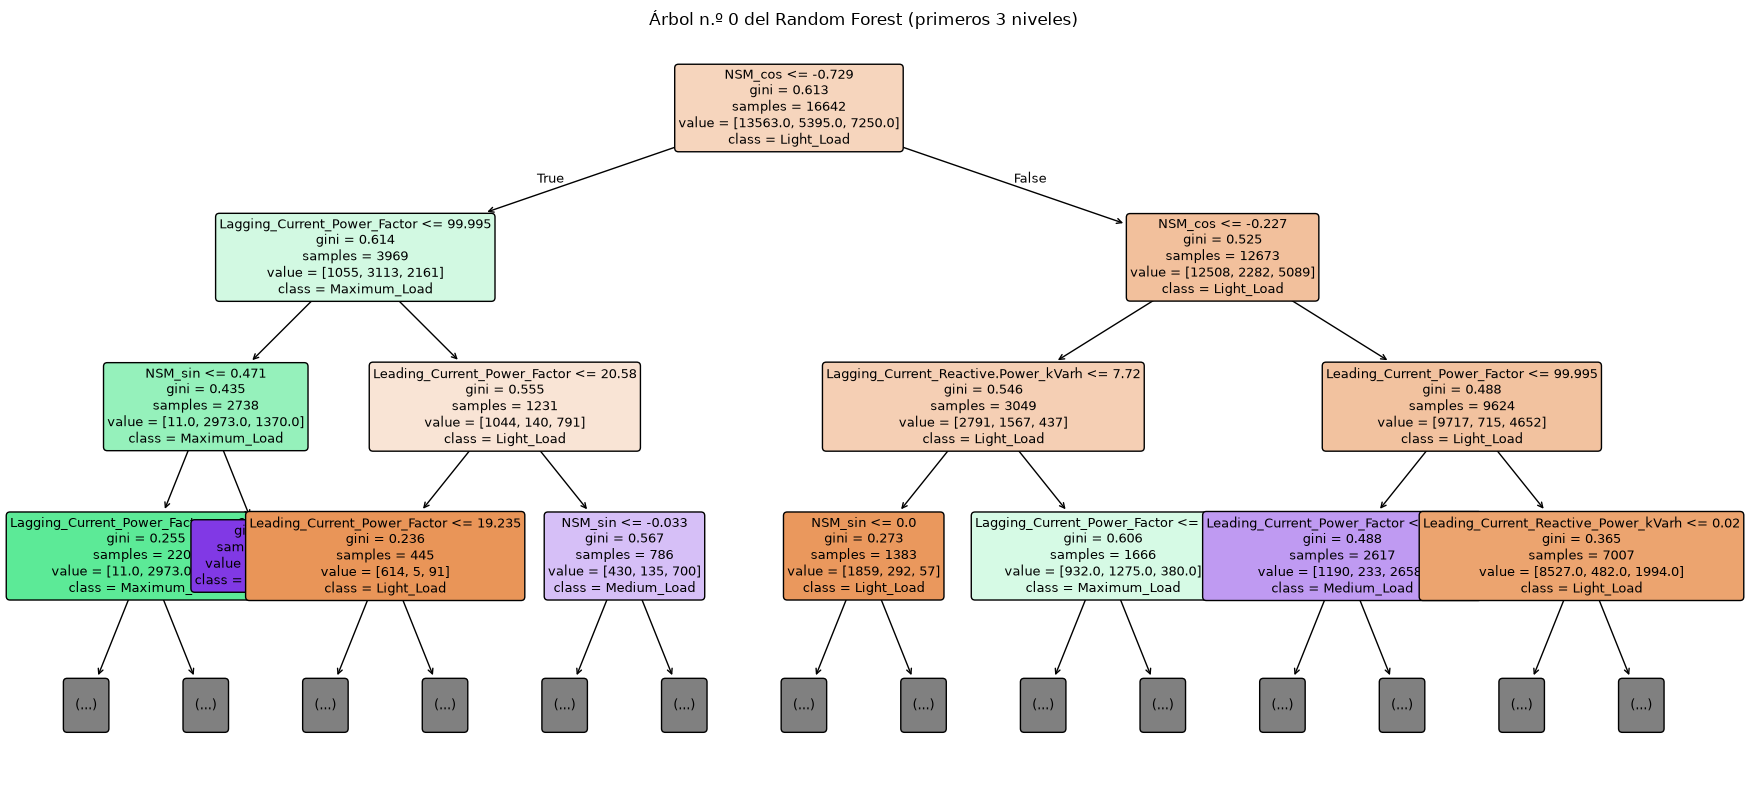

In [12]:
# Celda 4.7 (complementaria): un árbol del bosque y efecto de ponderar las clases
rf.graficar_arbol_del_bosque(modelo, list(X_tr.columns));
rf.comparar_class_weight(X_tr, X_te, y_tr, y_te, mejores)

**Árbol del bosque.** El gráfico muestra los primeros niveles de **uno** de los 200 árboles del bosque. Sirve para ilustrar que cada árbol es distinto de los demás e individualmente imperfecto; la solidez del modelo proviene de la votación conjunta.

**Ponderación de clases.** Se probó asignar más peso a las clases menos frecuentes (`class_weight="balanced"`), con la expectativa de detectar más cargas máximas. El resultado fue una exactitud levemente menor (0,7766 frente a 0,7833) y un recall de carga máxima apenas superior (0,5899 frente a 0,5806). **La mejora no compensa la pérdida**, por lo que se mantiene el modelo sin ponderar.

## 5. AdaBoost

AdaBoost (*Adaptive Boosting*) sigue una estrategia distinta a Random Forest. En lugar de entrenar árboles independientes, los entrena **en secuencia**:

1. se entrena un árbol muy simple (*aprendiz débil*);
2. se aumenta el peso de las mediciones que ese árbol clasificó mal;
3. el siguiente árbol se entrena prestando más atención a esos casos difíciles;
4. el proceso se repite y, al final, cada árbol vota con un peso proporcional a su acierto.

Mientras Random Forest busca reducir la **varianza** promediando modelos complejos, AdaBoost busca reducir el **sesgo** combinando modelos simples que se corrigen unos a otros.

In [13]:
# Celda 5.1: importar el módulo
from modelos_aprendizaje import adaboost as ab

In [14]:
# Celda 5.2: elección de hiperparámetros con validación cruzada temporal (solo entrenamiento)
mejores_ab, tabla_cv_ab = ab.buscar_hiperparametros(X_tr, y_tr)
print("Mejores parámetros:", mejores_ab)
tabla_cv_ab.head(10)

Mejores parámetros: {'max_depth': 2, 'learning_rate': 1.0, 'n_estimators': 200}


,max_depth,learning_rate,n_estimators,F1_macro_CV,Desv_CV,Ranking
0,2,1.0000,200,0.8437,0.0885,1
1,2,1.0000,50,0.8398,0.0954,2
2,2,0.5000,200,0.8390,0.0929,3
3,2,0.5000,50,0.8283,0.0855,4
4,3,0.5000,200,0.8266,0.1063,5
5,3,1.0000,50,0.8183,0.0902,6
6,3,0.5000,50,0.8079,0.1167,7
7,3,0.1000,200,0.8039,0.1156,8
8,3,1.0000,200,0.8032,0.0973,9
9,2,0.1000,200,0.7978,0.0752,10


**Qué muestra la tabla.** Igual que en Random Forest, se compararon configuraciones solo con el conjunto de entrenamiento. Aquí se variaron la profundidad de cada árbol (`max_depth`), la magnitud de cada corrección (`learning_rate`) y el número de árboles (`n_estimators`).

**Interpretación.** La mejor configuración usa **árboles de 2 niveles**, una tasa de aprendizaje de **1,0** y **200 árboles**, con un F1 de validación de **0,8437**, el valor más alto de todos los modelos en esta etapa. Las configuraciones con tasa 0,1 quedan entre las peores, porque con correcciones tan pequeñas el modelo aprende demasiado lento para el número de árboles disponible. Los árboles de 3 niveles tampoco superan a los de 2: aprendices más complejos se ajustan antes a los casos difíciles y dejan menos margen al refuerzo.

In [15]:
# Celda 5.3: entrenamiento y evaluación del modelo final
modelo_ab = ab.entrenar_adaboost(X_tr, y_tr, **mejores_ab)
metricas_ab, pred_ab = ab.evaluar_modelo(modelo_ab, X_tr, X_te, y_tr, y_te)
pd.DataFrame([metricas_ab])

,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,0.9053,0.7927,0.2073,0.7259,0.5768,0.5686


**Resultados.** AdaBoost obtiene una exactitud de **0,9053 en entrenamiento** y **0,7927 en prueba**, un F1 macro de **0,7259**, un recall de carga máxima de **0,5768** y una precisión de **0,5686**. Es el mejor resultado de prueba entre los modelos evaluados, aunque la ventaja sobre el árbol y el bosque es de pocas décimas de punto porcentual. Su diferencia entre entrenamiento y prueba (11 puntos) es menor que la de Random Forest (17 puntos), lo que indica un sobreajuste más moderado.

,N_estimadores,Accuracy_train,Accuracy_test,F1_macro_test
0,1,0.6894,0.5998,0.4694
1,10,0.8611,0.7697,0.6967
2,20,0.8872,0.7817,0.7176
3,30,0.8940,0.7834,0.7194
4,40,0.8969,0.7870,0.7220
5,50,0.8980,0.7868,0.7197
6,60,0.8996,0.7874,0.7208
7,70,0.9019,0.7854,0.7211
8,80,0.9019,0.7850,0.7200
9,90,0.9013,0.7859,0.7202


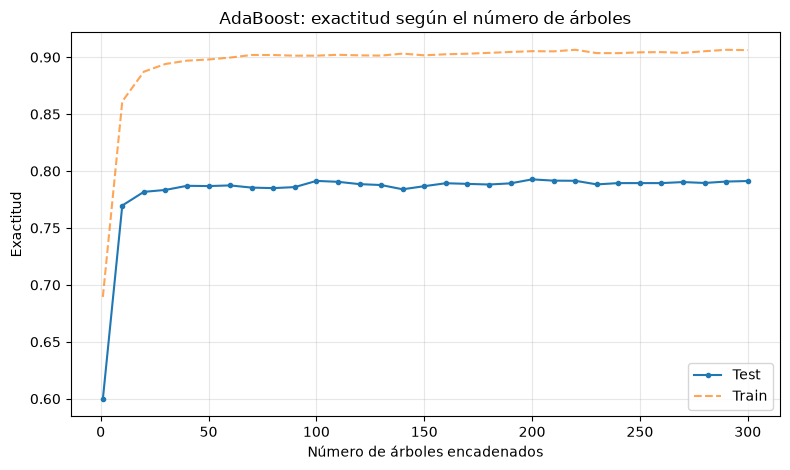

In [16]:
# Celda 5.4: efecto del número de árboles encadenados
curva_ab = ab.curva_n_estimadores(X_tr, X_te, y_tr, y_te, n_estimators=300,
                                  learning_rate=mejores_ab["learning_rate"],
                                  max_depth=mejores_ab["max_depth"])
display(curva_ab)
ab.graficar_curva_n_estimadores(curva_ab);

**Cómo leer el gráfico.** El eje horizontal indica cuántos árboles se han encadenado y el vertical, la exactitud. La línea punteada corresponde al entrenamiento y la continua, a la prueba.

**Interpretación.** El gráfico muestra el comportamiento característico del refuerzo:

- Con **1 árbol**, la exactitud de prueba es apenas **0,5998**.
- Con **10 árboles** salta a **0,7697**, y con **30** llega a **0,7834**.
- Desde ahí la curva es prácticamente **plana**, oscilando entre 0,784 y 0,793.

Las **primeras correcciones aportan casi toda la mejora**; las siguientes solo afinan detalles. Pasados unos 100 árboles no hay ganancias reales. A diferencia de lo que podría temerse, la curva de prueba no cae al agregar árboles, por lo que el modelo no muestra un sobreajuste creciente.

,Modelo,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,Árbol pequeño solo (prof. 2),0.6894,0.5998,0.4002,0.4694,0.7856,0.3781
1,AdaBoost,0.9053,0.7927,0.2073,0.7259,0.5768,0.5686


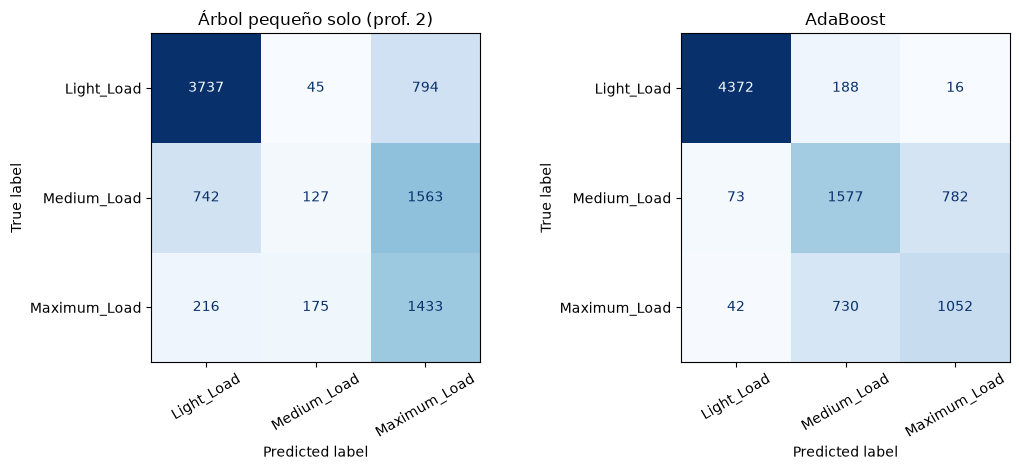

In [17]:
# Celda 5.5: un árbol pequeño aislado frente a AdaBoost, y matrices de confusión
tabla_cmp_ab, modelos_cmp_ab, preds_cmp_ab = ab.comparar_base_vs_refuerzo(X_tr, X_te, y_tr, y_te, mejores_ab)
display(tabla_cmp_ab)
ab.graficar_matrices_confusion(preds_cmp_ab, y_te);

**Resultados.**

| Modelo | Exactitud prueba | F1 macro | Recall Maximum | Precision Maximum |
|---|---|---|---|---|
| Árbol pequeño solo (prof. 2) | 0,5998 | 0,4694 | 0,7856 | 0,3781 |
| AdaBoost (200 árboles) | **0,7927** | **0,7259** | 0,5768 | **0,5686** |

**Interpretación.**

- El refuerzo transforma un modelo **débil** (60 % de exactitud) en uno **competitivo** (79 %): esta comparación demuestra directamente el aporte de AdaBoost.
- El árbol pequeño tiene un recall de carga máxima mayor (0,7856), pero con una precisión de solo 0,3781. En su matriz de confusión se aprecia por qué: **clasifica como carga máxima una gran parte de las mediciones de carga media e incluso liviana**. Detecta muchas cargas máximas porque alerta casi siempre, lo que lo haría inútil como sistema de alertas.
- La matriz de AdaBoost, en cambio, presenta una diagonal marcada y el mismo patrón de confusión media–máxima observado en los otros modelos.

In [18]:
# Celda 5.6: ¿conviene usar árboles base más grandes?
ab.comparar_aprendices_debiles(X_tr, X_te, y_tr, y_te, profundidades=(1, 2, 3, 5))

,Profundidad_base,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,1,0.8344,0.7615,0.2385,0.7071,0.7220,0.5719
1,2,0.9006,0.7850,0.2150,0.7186,0.5735,0.5600
2,3,0.9074,0.7860,0.2140,0.7217,0.5773,0.5698
3,5,0.9326,0.7923,0.2077,0.7299,0.6014,0.5786


**Resultados.**

| Profundidad de cada árbol | Exactitud entrenamiento | Exactitud prueba | F1 macro | Recall Maximum |
|---|---|---|---|---|
| 1 | 0,8344 | 0,7615 | 0,7071 | 0,7220 |
| 2 | 0,9006 | 0,7850 | 0,7186 | 0,5735 |
| 3 | 0,9074 | 0,7860 | 0,7217 | 0,5773 |
| 5 | 0,9326 | 0,7923 | 0,7299 | 0,6014 |

**Interpretación.** Pasar de árboles de 1 nivel a árboles de 2 niveles mejora claramente el resultado (de 0,7615 a 0,7850). Más allá de eso, las mejoras en prueba son pequeñas (hasta 0,7923), mientras que la exactitud de entrenamiento sigue subiendo (hasta 0,9326), lo que **amplía la brecha de sobreajuste**. Se mantiene la profundidad 2, elegida por validación, como equilibrio entre desempeño y simplicidad.

> *Nota:* los valores de esta tabla pueden diferir levemente de la celda 5.3 porque aquí se usa una configuración fija de comparación (200 árboles y una tasa de aprendizaje de 0,5, en vez de la tasa 1,0 del modelo final).

,Imp_impureza,Imp_permutacion,Desv_permutacion
NSM_sin,0.2119,0.2955,0.0050
NSM_cos,0.2110,0.0966,0.0019
Leading_Current_Power_Factor,0.1904,0.0523,0.0024
Leading_Current_Reactive_Power_kVarh,0.1126,0.0263,0.0013
Lagging_Current_Power_Factor,0.1488,0.0131,0.0021
Lagging_Current_Reactive.Power_kVarh,0.1166,0.0115,0.0016
WeekStatus_bin,0.0087,0.0113,0.0012


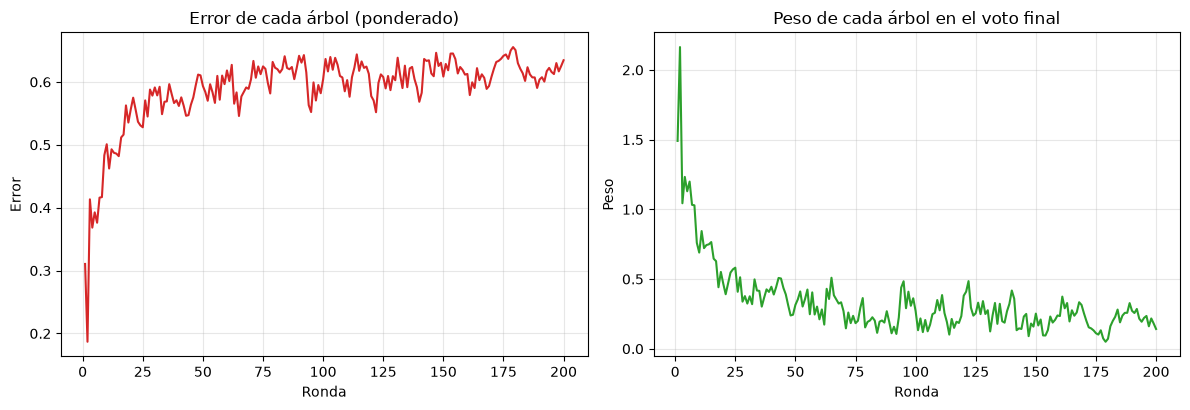

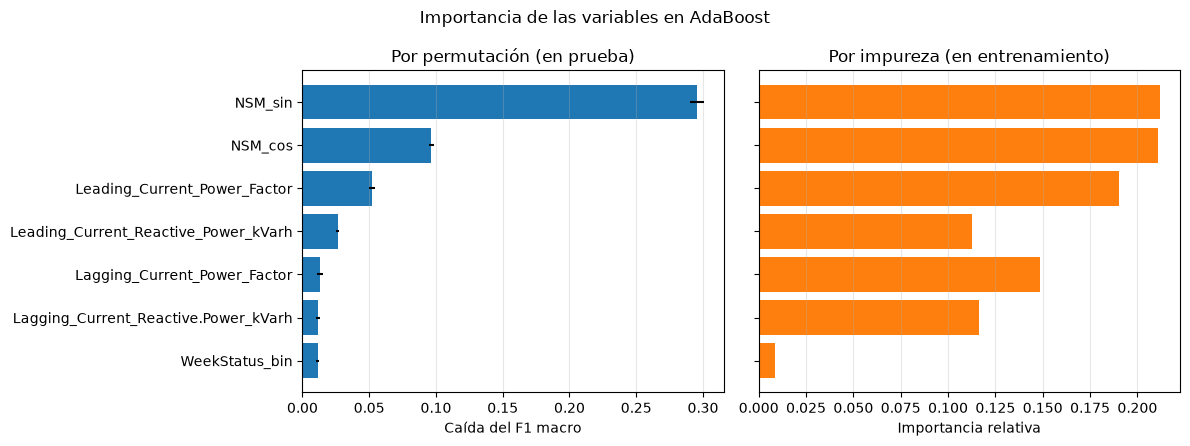

In [19]:
# Celda 5.7: funcionamiento interno del refuerzo e importancia de variables
ab.graficar_rondas(modelo_ab);
imp_ab = ab.tabla_importancias(modelo_ab, X_te, y_te)
display(imp_ab)
ab.graficar_importancias(imp_ab);

**Gráficos de rondas.** Permiten observar el mecanismo de AdaBoost:

- **Error de cada árbol (ponderado):** el error crece con las rondas y se acerca a 0,5. Esto no es una falla: a medida que avanza el proceso, cada nuevo árbol se entrena sobre los casos **más difíciles**, que los anteriores no lograron resolver, por lo que naturalmente se equivoca más.
- **Peso de cada árbol en el voto final:** los primeros árboles, más certeros, reciben pesos altos; los últimos, pesos bajos. En otras palabras, el modelo **confía más en los árboles que resolvieron los casos generales** y usa los posteriores para ajustes finos.

**Importancia de variables.** Por permutación, la **hora del día** vuelve a ser la variable dominante (`NSM_sin` 0,2955; `NSM_cos` 0,0966), seguida del **factor de potencia capacitivo** (0,0523) y la **reactiva capacitiva** (0,0263). El tipo de día tiene un efecto reducido (0,0113). Este orden coincide con el de Random Forest: dos métodos con lógicas distintas llegan a la **misma conclusión**, lo que le da solidez.

## 6. Redes bayesianas

### 6.1 Concepto

Una red bayesiana es un **grafo dirigido acíclico** en que cada nodo es una variable y cada flecha $A \rightarrow B$ indica que $A$ influye directamente en $B$. Cada nodo tiene asociada una **tabla de probabilidad condicional** (CPT), que indica la probabilidad de cada valor del nodo dados los valores de sus padres. La probabilidad conjunta de todas las variables se obtiene como:

$$P(X_1,\dots,X_n)=\prod_{i=1}^{n} P\big(X_i \mid \text{padres}(X_i)\big)$$

Para clasificar una medición, la red calcula $P(\text{Load\_Type}\mid\text{evidencia})$ y elige la clase más probable. A diferencia de los modelos anteriores, la red **entrega probabilidades explícitas** y permite hacer consultas con información parcial (por ejemplo, conociendo solo la hora y el tipo de día).

> **Nota de implementación:** la red se implementó con `numpy` y `pandas` en `src/modelos_aprendizaje/redes_bayesianas.py` (aprendizaje de estructura, estimación de CPT con suavizado de Laplace e inferencia exacta por enumeración), ya que la librería `pgmpy` no estaba disponible en el entorno de trabajo.

### 6.2 Variables de la red y discretización

Este tipo de red trabaja con **variables categóricas**, por lo que las variables numéricas deben **discretizarse** en niveles. Los cortes se obtuvieron con **cuantiles** del conjunto de entrenamiento, de modo que cada nivel contenga una cantidad similar de observaciones.

| Nodo | Variable de origen | Niveles | Por qué se incluye |
|---|---|---|---|
| `Load_Type` | Etiqueta original | Light / Medium / Maximum | Es la variable que se busca predecir y vigilar. |
| `Franja_horaria` | `NSM_sin`, `NSM_cos` (se recupera la hora) | Madrugada (0–6 h), Mañana (6–12 h), Tarde (12–18 h), Noche (18–24 h) | Fue la variable más importante en Random Forest y AdaBoost; las franjas son fáciles de interpretar operativamente. |
| `Tipo_dia` | `WeekStatus_bin` | Hábil / Fin de semana | La actividad productiva difiere entre semana y fin de semana. |
| `Reactiva_inductiva` | Energía reactiva inductiva | Bajo ≤ 3,92 · Medio 3,92–9,65 · Alto > 9,65 | Refleja cuánta maquinaria pesada está en operación. |
| `Reactiva_capacitiva` | Energía reactiva capacitiva | Bajo ≤ 0 · Alto > 0 | Casi siempre vale 0; lo informativo es si aparece o no. |
| `FP_inductivo` | Factor de potencia inductivo | Bajo ≤ 70,40 · Medio 70,40–94,85 · Alto > 94,85 | Resume la eficiencia eléctrica del régimen de trabajo. |
| `FP_capacitivo` | Factor de potencia capacitivo | Bajo ≤ 100 · Alto > 100 | Distingue si existe componente capacitiva. |

Las variables reactiva capacitiva y factor de potencia capacitivo quedan con solo **dos niveles** porque gran parte de sus valores se concentran en un único punto (0 y 100, respectivamente), lo que impide formar tres grupos de igual tamaño.

### 6.3 Estructuras comparadas

1. **Naive Bayes:** todas las variables dependen únicamente de `Load_Type`, y se supone que son independientes entre sí una vez conocida la carga. Es la estructura más simple y sirve como línea base.
2. **Experta:** diseñada con conocimiento del dominio. La franja horaria y el tipo de día influyen en el tipo de carga; el tipo de carga se manifiesta en las cuatro mediciones eléctricas; y cada potencia reactiva influye en su factor de potencia correspondiente.
3. **Aprendida (BIC):** la estructura se obtiene de los datos mediante búsqueda *Hill Climbing*, maximizando el criterio **BIC** (*Bayesian Information Criterion*), que premia el buen ajuste y penaliza la complejidad. Se permitió un máximo de 3 padres por nodo y se prohibió que la franja horaria o el tipo de día tuvieran padres, ya que ninguna variable eléctrica puede "causar" la hora o el día de la semana.

In [20]:
# Celda 6.1: importar el módulo y verificar la hora y el tipo de día
from modelos_aprendizaje import redes_bayesianas as rb

display(pd.DataFrame({"hora_derivada": rb.hora_del_dia(X_tr),
                      "hora_real": df.loc[X_tr.index, "NSM"] / 3600}).head())
pd.crosstab(X_tr["WeekStatus_bin"], df.loc[X_tr.index, "WeekStatus"])

,hora_derivada,hora_real
0,0.0000,0.0000
1,0.2500,0.2500
2,0.5000,0.5000
3,0.7500,0.7500
4,1.0000,1.0000


WeekStatus,Weekday,Weekend
WeekStatus_bin,,
0,18720,0
1,0,7488


**Qué muestra.** Dos verificaciones previas a la discretización:

1. La hora reconstruida a partir del seno y el coseno (`hora_derivada`) **coincide exactamente** con la hora original (`hora_real`), lo que garantiza que las franjas horarias se asignan correctamente.
2. La tabla cruzada confirma que `WeekStatus_bin = 1` corresponde a **fin de semana** (7.488 mediciones) y `0` a **día hábil** (18.720), sin ningún caso mal codificado.

Estas verificaciones evitan que un error de codificación invierta el significado de las variables y, con ello, las conclusiones.

In [21]:
# Celda 6.2: entrenamiento y comparación de las tres estructuras
tabla_rb, redes, preds_rb = rb.comparar_estructuras(X_tr, X_te, y_tr, y_te)
tabla_rb

,Estructura,N_flechas,N_parametros,BIC_train,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,Naive Bayes,6,32,-129777.9000,0.7018,0.6031,0.3969,0.5686,0.6765,0.4356
1,Experta,8,53,-119603.6000,0.7430,0.6669,0.3331,0.6207,0.5844,0.4453
2,Aprendida (BIC),11,177,-102210.3000,0.7682,0.6915,0.3085,0.6364,0.5970,0.4447


**Cómo leer la tabla.** `N_flechas` y `N_parametros` miden la complejidad de la red (número de relaciones y de probabilidades a estimar). `BIC_train` evalúa el equilibrio entre ajuste y complejidad: **mientras menos negativo, mejor**.

**Resultados.**

| Estructura | Flechas | Parámetros | BIC | Exactitud prueba | F1 macro | Recall Maximum | Precision Maximum |
|---|---|---|---|---|---|---|---|
| Naive Bayes | 6 | 32 | −129.778 | 0,6031 | 0,5686 | 0,6765 | 0,4356 |
| Experta | 8 | 53 | −119.604 | 0,6669 | 0,6207 | 0,5844 | 0,4453 |
| Aprendida (BIC) | 11 | 177 | **−102.210** | **0,6915** | **0,6364** | 0,5970 | 0,4447 |

**Interpretación.**

- Las tres estructuras se ordenan igual en BIC y en desempeño de prueba: **Naive Bayes < Experta < Aprendida**.
- Naive Bayes es la más débil porque su supuesto de independencia no se cumple: en una planta, la potencia reactiva y el factor de potencia están **físicamente relacionados**, y la hora condiciona a todas las mediciones.
- La estructura experta mejora al incorporar la hora y el tipo de día como causas de la carga, pero la **aprendida** la supera al descubrir relaciones adicionales en los datos.
- Aun la mejor red queda por debajo de los modelos de árboles (0,6915 frente a ≈ 0,79). Esto se explica en parte porque la discretización **reduce información**: al convertir un valor continuo en "bajo / medio / alto", se pierden las diferencias finas dentro de cada nivel.

In [22]:
# Celda 6.3: cortes de la discretización y flechas de la red aprendida
red = redes["Aprendida (BIC)"]
display(rb.tabla_cortes(red))
rb.tabla_arcos(red)

,Variable,Origen,Niveles
0,Franja_horaria,NSM_sin / NSM_cos,Madrugada 0-6 h | Mañana 6-12 h | Tarde 12-18 ...
1,Tipo_dia,WeekStatus_bin,Hábil | Fin de semana (valor 1)
2,Reactiva_inductiva,Lagging_Current_Reactive.Power_kVarh,Bajo: ≤ 3.92 | Medio: 3.92 a 9.65 | Alto: > 9.65
3,Reactiva_capacitiva,Leading_Current_Reactive_Power_kVarh,Bajo: ≤ 0.00 | Alto: > 0.00
4,FP_inductivo,Lagging_Current_Power_Factor,Bajo: ≤ 70.40 | Medio: 70.40 a 94.85 | Alto: >...
5,FP_capacitivo,Leading_Current_Power_Factor,Bajo: ≤ 100.00 | Alto: > 100.00


,Padre,Hijo
0,Franja_horaria,Load_Type
1,Tipo_dia,Load_Type
2,Load_Type,Reactiva_inductiva
3,Franja_horaria,Reactiva_inductiva
4,Tipo_dia,Reactiva_inductiva
5,Franja_horaria,Reactiva_capacitiva
6,Reactiva_inductiva,Reactiva_capacitiva
7,FP_inductivo,Reactiva_capacitiva
8,Load_Type,FP_inductivo
9,Franja_horaria,FP_inductivo


**Tabla de cortes.** Es el "diccionario" de la discretización: indica qué valores numéricos corresponden a cada nivel (por ejemplo, la reactiva inductiva es *Alta* cuando supera 9,65 kVarh).

**Tabla de flechas.** Lista las relaciones *padre → hijo* que encontró el algoritmo. Las más relevantes son:

- **`Franja_horaria → Load_Type`** y **`Tipo_dia → Load_Type`**: el tipo de carga depende directamente del momento del día y del tipo de día, lo que coincide con la importancia de variables de los modelos de ensamble.
- **`Load_Type → Reactiva_inductiva`** y **`Load_Type → FP_inductivo`**: el régimen de carga se refleja en estas dos mediciones eléctricas.
- **`Reactiva_inductiva → FP_inductivo`**: relación física esperable, ya que el factor de potencia depende de la proporción de energía reactiva.
- La **reactiva capacitiva** depende de la hora, de la reactiva inductiva y del factor de potencia inductivo: se comporta como un efecto secundario del funcionamiento de los equipos.
- **`FP_capacitivo` no tiene ninguna flecha**: la red concluyó que, conocidas las demás variables, no aporta información adicional.

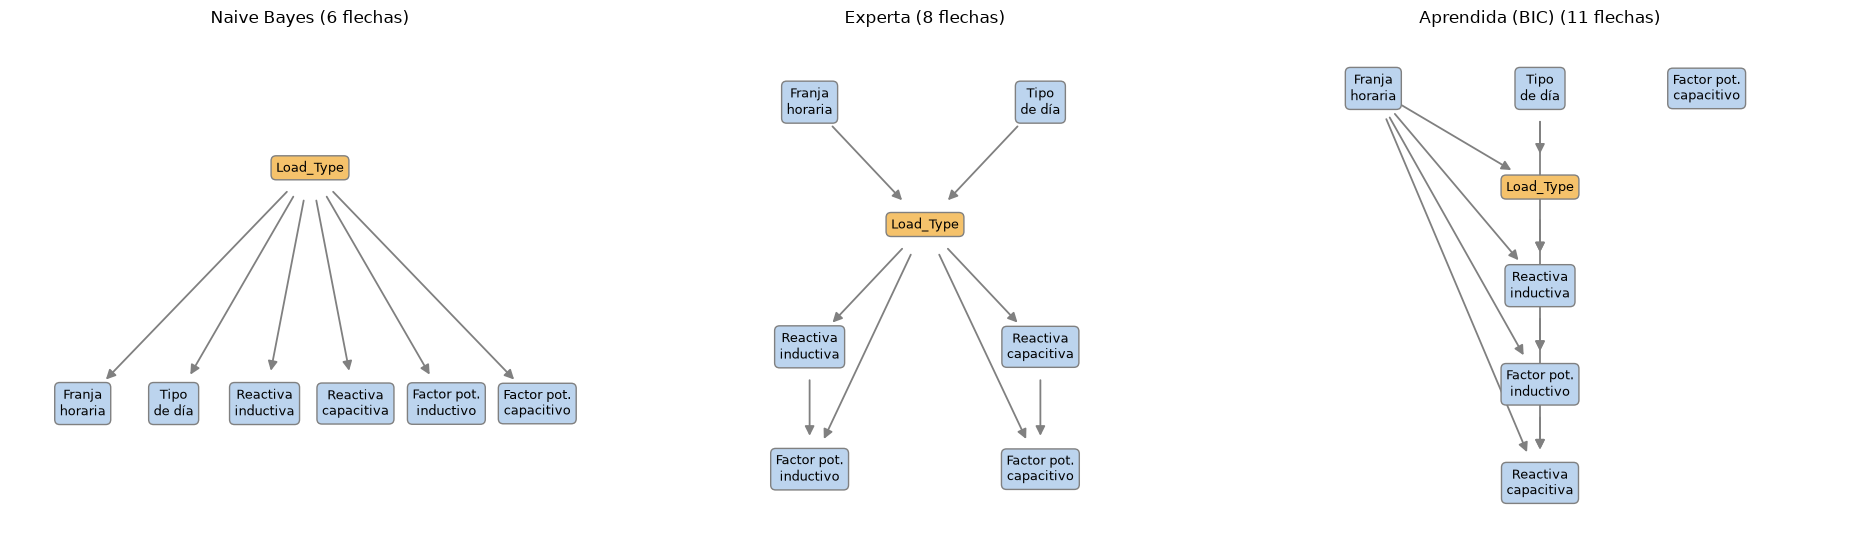

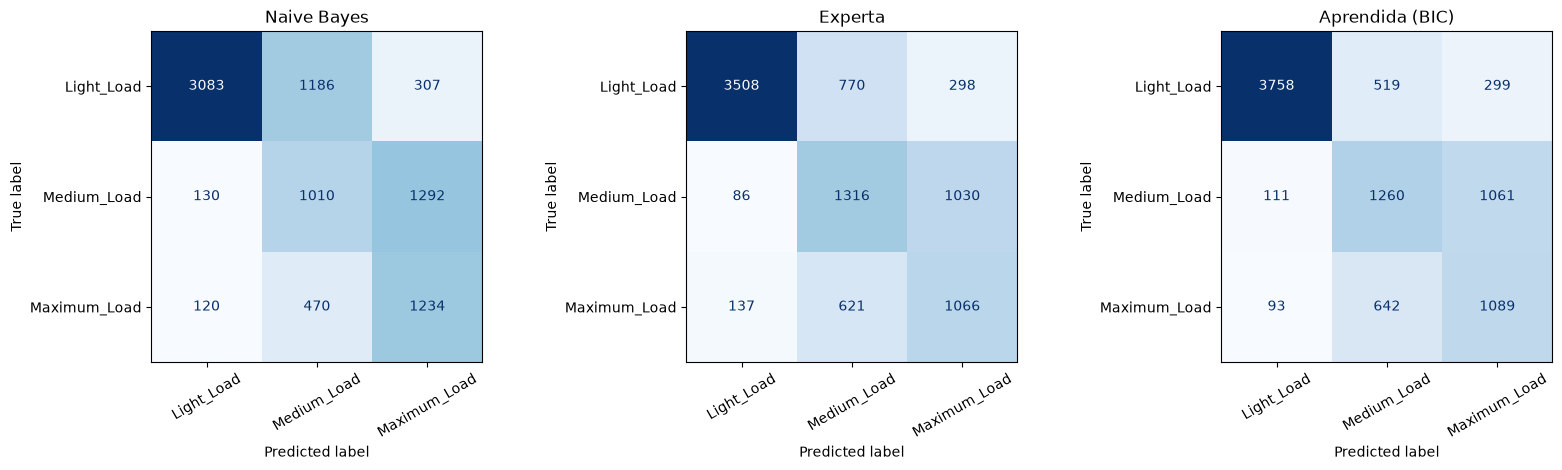

In [23]:
# Celda 6.4: grafos de las tres redes y matrices de confusión
rb.graficar_redes(redes);
rb.graficar_matrices_confusion(preds_rb, y_te);

**Cómo leer los grafos.** Cada recuadro es una variable y cada flecha, una influencia directa. Las variables se ordenan por niveles: arriba las que no tienen padres (causas) y abajo sus efectos.

- **Naive Bayes** tiene forma de **estrella**: todas las flechas salen de `Load_Type`.
- **Experta** muestra la hipótesis de diseño: hora y tipo de día → carga → mediciones eléctricas.
- **Aprendida (BIC)** es la más densa: además de las relaciones con la carga, incluye relaciones **entre las propias variables eléctricas**, que las otras dos estructuras ignoraban.

**Matrices de confusión.** Se leen igual que en la sección 3. En las tres redes la diagonal es menos marcada que en los modelos de árboles, y la confusión entre carga media y máxima sigue siendo la principal fuente de error.

In [24]:
# Celda 6.5: tabla de probabilidad condicional de Load_Type
rb.tabla_cpt(red, "Load_Type")

Light_Load  Medium_Load  Maximum_Load
Franja_horaria Tipo_dia                                            
Madrugada      Hábil              0.9996       0.0002        0.0002
               Fin de semana      0.9989       0.0005        0.0005
Mañana         Hábil              0.5674       0.1574        0.2753
               Fin de semana      0.7467       0.0923        0.1611
Tarde          Hábil              0.0566       0.3835        0.5599
               Fin de semana      0.4485       0.2096        0.3419
Noche          Hábil              0.1745       0.7171        0.1085
               Fin de semana      0.5173       0.4336        0.0491

**Cómo leer la tabla.** Cada fila es una situación (franja horaria + tipo de día) y cada columna, la probabilidad de cada tipo de carga en esa situación; las tres probabilidades de una fila suman 1.

**Interpretación.**

- En la **madrugada** la carga es liviana prácticamente siempre (≈ 99,9 %), sin importar el día.
- La **tarde de un día hábil** es la situación de **mayor riesgo**: 56 % de probabilidad de carga máxima y solo 5,7 % de carga liviana.
- En **fin de semana** el riesgo disminuye en todas las franjas (por ejemplo, la carga máxima de tarde baja de 56 % a 34 %).
- En la **noche de días hábiles** predomina la carga media (72 %).

Esta tabla funciona como un **calendario de riesgo** de la planta y puede usarse directamente para definir en qué momentos activar una vigilancia más estricta.

In [25]:
# Celda 6.6: consultas a la red (escenarios de alerta)
for evid in [{"Franja_horaria": "Madrugada", "Tipo_dia": "Hábil"},
             {"Franja_horaria": "Tarde", "Tipo_dia": "Hábil"},
             {"Franja_horaria": "Tarde", "Tipo_dia": "Fin de semana"},
             {"Franja_horaria": "Tarde", "Tipo_dia": "Hábil", "FP_inductivo": "Alto"}]:
    print(evid)
    display(red.consulta(evid).round(3).to_frame().T)

{'Franja_horaria': 'Madrugada', 'Tipo_dia': 'Hábil'}


,Light_Load,Medium_Load,Maximum_Load
P(Load_Type | evidencia),1.0000,0.0000,0.0000


{'Franja_horaria': 'Tarde', 'Tipo_dia': 'Hábil'}


,Light_Load,Medium_Load,Maximum_Load
P(Load_Type | evidencia),0.0570,0.3840,0.5600


{'Franja_horaria': 'Tarde', 'Tipo_dia': 'Fin de semana'}


,Light_Load,Medium_Load,Maximum_Load
P(Load_Type | evidencia),0.4490,0.2100,0.3420


{'Franja_horaria': 'Tarde', 'Tipo_dia': 'Hábil', 'FP_inductivo': 'Alto'}


,Light_Load,Medium_Load,Maximum_Load
P(Load_Type | evidencia),0.1310,0.5620,0.3080


**Qué muestra.** Consultas del tipo *"dada esta información, ¿qué probabilidad tiene cada tipo de carga?"*. La red combina la evidencia disponible con sus tablas de probabilidad y recalcula la distribución de `Load_Type`.

**Interpretación.**

| Evidencia | Light | Medium | Maximum |
|---|---|---|---|
| Madrugada, día hábil | 1,000 | 0,000 | 0,000 |
| Tarde, día hábil | 0,057 | 0,384 | **0,560** |
| Tarde, fin de semana | 0,449 | 0,210 | 0,342 |
| Tarde, día hábil, FP inductivo **alto** | 0,131 | **0,562** | 0,308 |

El último escenario es el más ilustrativo: al saber además que el factor de potencia inductivo es **alto**, la probabilidad de carga máxima baja de 56 % a 31 % y la carga media pasa a ser la más probable. Es decir, la red **actualiza su estimación cuando llega nueva información**, que es exactamente el razonamiento que requiere un sistema de alertas: empezar con una estimación basada en el horario y refinarla con las mediciones en tiempo real.

In [26]:
# Celda 6.7: sensibilidad al número de niveles de la discretización
rb.comparar_n_bins(X_tr, X_te, y_tr, y_te, valores=(2, 3, 4, 5))

,Niveles_por_variable,N_flechas,N_parametros,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,2,11,77,0.7543,0.6793,0.3207,0.6223,0.5115,0.4693
1,3,11,177,0.7682,0.6915,0.3085,0.6364,0.5970,0.4447
2,4,14,332,0.7811,0.7180,0.2820,0.6334,0.4967,0.4532
3,5,14,686,0.7784,0.6741,0.3259,0.6093,0.6261,0.4457


**Interpretación.** El desempeño **depende de cómo se discretiza**. Con 2 niveles se pierde demasiada información; con 4 se alcanza la mayor exactitud (0,7180), pero el recall de carga máxima cae a 0,4967; con 5 niveles el número de parámetros se dispara (686) y muchas combinaciones quedan con muy pocos datos para estimarlas, por lo que el desempeño empeora. Se mantiene la red de **3 niveles**, que obtiene el mejor F1 macro, un recall de carga máxima razonable y tablas de probabilidad más fáciles de interpretar.

## 7. Comparación final de los modelos

Se comparan los cuatro modelos seleccionados sobre el mismo conjunto de prueba (octubre–diciembre).

,Modelo,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,"Árbol (Gini, prof. 5)",0.8805,0.7885,0.2115,0.7194,0.5998,0.5622
1,Random Forest,0.9502,0.7833,0.2167,0.7194,0.5806,0.5765
2,AdaBoost,0.9053,0.7927,0.2073,0.7259,0.5768,0.5686
3,Red bayesiana,0.7682,0.6915,0.3085,0.6364,0.5970,0.4447


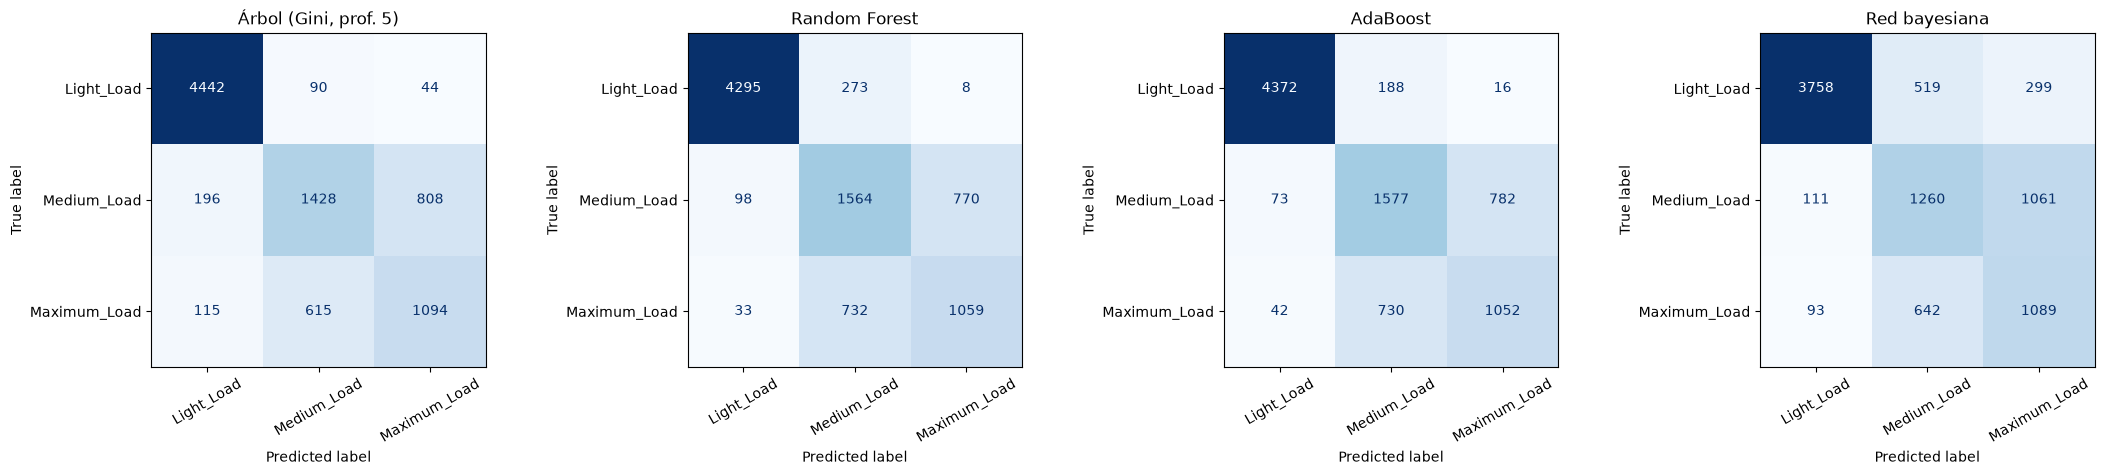

In [27]:
# Celda 7.1: tabla comparativa y matrices de confusión
modelos_finales = {
    "Árbol (Gini, prof. 5)": modelos[("gini", 5)],
    "Random Forest": modelo,
    "AdaBoost": modelo_ab,
    "Red bayesiana": red,
}
tabla_final, preds_final = ab.comparar_modelos(modelos_finales, X_tr, X_te, y_tr, y_te)
display(tabla_final)
ab.graficar_matrices_confusion(preds_final, y_te);

**Resultados.**

| Modelo | Exactitud entrenamiento | Exactitud prueba | F1 macro | Recall Maximum | Precision Maximum |
|---|---|---|---|---|---|
| Árbol (Gini, prof. 5) | 0,8805 | 0,7885 | 0,7194 | **0,5998** | 0,5622 |
| Random Forest | 0,9502 | 0,7833 | 0,7194 | 0,5806 | **0,5765** |
| **AdaBoost** | 0,9053 | **0,7927** | **0,7259** | 0,5768 | 0,5686 |
| Red bayesiana | 0,7682 | 0,6915 | 0,6364 | 0,5970 | 0,4447 |
| *KNN (Tarea 3, referencia)* | — | *≈ 0,78* | *≈ 0,72* | *≈ 0,60* | — |

**Interpretación.**

- **Los tres modelos basados en árboles son prácticamente equivalentes.** Sus exactitudes de prueba difieren en menos de un punto porcentual (78,3 %–79,3 %) y su F1 macro, en menos de una centésima. AdaBoost obtiene el mejor valor, pero la diferencia es demasiado pequeña para considerarla una ventaja real.
- **La red bayesiana es menos exacta** (69,2 %) y genera más falsas alarmas (precisión 0,4447), pero **detecta la carga máxima tan bien como los demás** (recall 0,5970) y es la única que entrega probabilidades interpretables.
- **Las cuatro matrices de confusión muestran el mismo patrón:** la carga liviana se reconoce casi perfectamente y los errores se concentran entre carga media y máxima. Que cuatro técnicas tan distintas fallen en el mismo lugar indica que el límite está en la **información contenida en las variables**, no en el algoritmo.
- Los resultados son muy similares a los de **KNN en la Tarea 3**, lo que refuerza la conclusión anterior: modelos de naturaleza muy distinta convergen a un mismo techo de desempeño.

## 8. Discusión y conclusiones

### 8.1 Respecto de lo solicitado en la tarea

- **Criterios de división del árbol.** Gini, entropía y error de clasificación producen resultados similares cuando el árbol tiene profundidad suficiente (5 niveles: 76,9 %–78,9 % de exactitud). Las diferencias se notan en árboles poco profundos, donde el error de clasificación —menos sensible a cambios pequeños de pureza— elige divisiones distintas. **La profundidad influyó mucho más que el criterio.**
- **Profundidad 3 y 5.** Los árboles de 3 niveles son fáciles de leer, pero insuficientes para separar tres clases (62 %–74 %). Los de 5 niveles mejoran el desempeño (77 %–79 %) a cambio de ser menos legibles y mostrar algo de sobreajuste.
- **Random Forest y AdaBoost.** Ninguno de los dos métodos de ensamble mejoró de forma relevante al árbol individual. Random Forest redujo las falsas alarmas y AdaBoost obtuvo el mejor resultado global, pero ambos chocan con el mismo límite.
- **Redes bayesianas.** La estructura aprendida con BIC superó a la experta y a Naive Bayes. Aunque su exactitud es menor que la de los árboles, ofrece algo que los demás modelos no ofrecen: **probabilidades explícitas y razonamiento con información parcial**.

### 8.2 Qué se puede rescatar de este trabajo

1. **La hora del día es el principal determinante de la carga.** Random Forest, AdaBoost y la red bayesiana coinciden en ello. En la práctica, buena parte del riesgo puede anticiparse **solo con el calendario**: la madrugada es casi siempre de carga liviana y la tarde de los días hábiles concentra la carga máxima (56 % de probabilidad).
2. **La carga liviana es fácil de reconocer; la frontera entre carga media y máxima no.** Más de tres cuartas partes de los errores de todos los modelos ocurren en esa frontera. Este es el hallazgo más importante para el sistema de alertas: el modelo puede descartar con mucha seguridad los periodos de bajo riesgo, pero dentro de los periodos de actividad su capacidad de distinguir el nivel exacto es limitada.
3. **Más complejidad no implica mejores resultados.** Un árbol de 25 hojas, que puede explicarse como un conjunto de reglas, rinde prácticamente lo mismo que un bosque de 200 árboles o que 200 árboles encadenados. Para una planta, esto favorece las soluciones **interpretables**, que el personal puede entender, validar y en las que puede confiar.
4. **El límite está en los datos, no en el algoritmo.** Todas las técnicas —y también KNN en la Tarea 3— convergen a cerca de 79 % de exactitud y a una detección de carga máxima del 58 %–60 %. Para mejorar el sistema, el camino no es probar algoritmos más sofisticados, sino **incorporar nueva información**: programación de la producción, turnos, equipos en operación, temperatura o el valor de la carga en los intervalos anteriores.
5. **Cada modelo tiene un rol distinto en el sistema propuesto.** Se recomienda usar un clasificador basado en árboles (árbol de decisión o AdaBoost) para la **clasificación automática** de cada medición, y la red bayesiana como herramienta de **análisis de escenarios y definición de umbrales** de alerta (*"¿qué tan probable es la carga máxima si es tarde de un día hábil y el factor de potencia está bajo?"*). Esta combinación integra precisión e interpretabilidad, y encaja con el componente de LangChain del proyecto, que podría traducir las probabilidades y reglas en mensajes comprensibles para los operadores.

### 8.3 Limitaciones

- Los datos corresponden a **un solo año y una sola planta**, por lo que los patrones encontrados podrían no generalizarse.
- El periodo de prueba (octubre–diciembre) resultó **más difícil** que los meses usados para entrenar y validar (F1 de validación ≈ 0,83 frente a 0,72 en prueba), lo que sugiere efectos estacionales no capturados por las variables actuales.
- Los resultados de la red bayesiana **dependen de la discretización**: con otros cortes o número de niveles, la exactitud varía entre 67 % y 72 %.
- **Alcance del modelo.** Como la etiqueta se deriva del consumo (que no se usa como predictor), los modelos reconocen el régimen de carga a partir de la hora y de las variables eléctricas, pero no pronostican la carga futura. Como **trabajo futuro** se propone predecir la carga de las próximas horas incorporando el consumo de intervalos anteriores (variables *lag*) y el calendario, con una validación que respete el orden temporal.
- No se evaluó el costo económico de cada tipo de error; un sistema real debería ajustar el umbral de alerta según el costo relativo de una falsa alarma frente a una carga máxima no detectada.

---